# Phase E - Bang danh gia cho bai bao (MEAD, 4 speaker test chua tung thay)

Tat ca mo hinh duoc danh gia tren **cung du lieu**, **cung cach can thoi gian** (tim do tre tot nhat tren val cho
tung mo hinh, ke ca baseline), **cung cac metric**:

| Nhom | Metric | Y nghia | Nguon |
| :--- | :--- | :--- | :--- |
| Do chinh xac | **LMD** toan mat / mieng (thap = tot) | sai so 68 diem so voi that, ke ca bieu cam tinh | MakeItTalk, Phase A/B |
| Chuyen dong | **M-LMD** mieng (chi chuyen dong trong clip) | bo bieu cam tinh, chi xet khau hinh | Phase B |
| | **LVD** mieng (thap = tot) | sai so van toc, chiu trach nhiem do giat | SAiD, ProbTalk, Tiny |
| | **Rung** = gia toc TB du doan / that (gan 1 = tot) | > 1: rung, < 1: qua mem | Tiny (velocity loss chong jitter) |
| | **Bien do** = do lech chuan do mo mieng du doan / that (gan 1) | < 1: mieng "luoi", mo it | Phase B |
| | **Tuong quan** do mo mieng (cao = tot) | dong bo nhip mo / khep | Phase B |
| Phan bo | **FD** mieng (thap = tot) | khoang cach Frechet giua phan bo chuyen dong that va sinh ra | SAiD (FD), ProbTalk (FGD) |
| Im lang | **Khep khi im** (thap = tot) | sai so khe moi o cac khung im lang | Tiny (lip closure) |
| Cam xuc | **Emo-Acc** toan mat / chi chuyen dong (cao = tot) | bo phan loai cam xuc train tren landmark THAT doan dung cam xuc yeu cau? | EAMM, EAT |
| Hieu nang | **Tham so**, **thoi gian / 1 s audio** (CPU, GPU) | nhe, chay thoi gian thuc | Tiny |

Baseline **MakeItTalk goc** (AutoVC + nhanh noi dung + nhanh speaker-aware, checkpoint cua tac gia) duoc chay lai
tren cung audio MEAD (Cell 5). MakeItTalk khong co dau vao cam xuc -> so sanh cong bang nhat la cac metric
**chuyen dong** + **Emo-Acc**.

Ket qua luu o `student_a2l/phaseE/`: `phaseE_results.json`, `phaseE_table.csv`, `phaseE_table.md` (dan vao bao cao),
`phaseE_bars.png`, `phaseE_mouth_example.png`.

## Cell 0 - Mount Drive va tu tim thu muc du lieu (dung duoc voi tai khoan Google khac co shortcut)

In [ ]:
# Cell 0 - Mount Drive + TU TIM thu muc du lieu (chay duoc ca khi dung tai khoan Google khac, co shortcut)
import os, sys, glob
from pathlib import Path

DRIVE_ROOT_OVERRIDE = ''      # neu tu tim sai: dien tay, vd '/content/drive/MyDrive/DAT301m/Data_student'
MEAD_ROOT_OVERRIDE  = ''      # vd '/content/drive/.shortcut-targets-by-id/1GwXP.../MEAD'

if 'google.colab' in sys.modules and not os.path.isdir('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')


def _is_data_root(p):
    # thu muc Data_student that: co du lieu MEAD da xu ly hoac thu muc ket qua student_a2l
    return os.path.isdir(os.path.join(p, 'Data_emotion_mead_task_b')) or os.path.isdir(os.path.join(p, 'student_a2l'))


def _is_mead(p):
    return os.path.isdir(p) and any(os.path.isfile(os.path.join(p, d, 'audio.tar')) for d in ('M003', 'M005', 'W033', 'M032'))


def _score(p):
    # 3: co du lieu MEAD da xu ly (split.json) | 2: co thu muc MEAD da xu ly | 1: chi co thu muc ket qua student_a2l
    if os.path.isfile(os.path.join(p, 'Data_emotion_mead_task_b', 'phaseB_ready', 'split.json')):
        return 3
    if os.path.isdir(os.path.join(p, 'Data_emotion_mead_task_b')):
        return 2
    return 1 if os.path.isdir(os.path.join(p, 'student_a2l')) else 0


def find_drive_root():
    if DRIVE_ROOT_OVERRIDE:
        return Path(DRIVE_ROOT_OVERRIDE)
    base = '/content/drive'
    cands = [base + '/MyDrive/DAT301m/Data_student']
    # shortcut nam o MyDrive (ten bat ky), shortcut tro toi DAT301m hoac Data_student, thu muc chia se (Shared drives)
    for pat in ('/MyDrive/*/Data_student', '/MyDrive/*/*/Data_student', '/MyDrive/Data_student',
                '/.shortcut-targets-by-id/*/DAT301m/Data_student', '/.shortcut-targets-by-id/*/Data_student',
                '/.shortcut-targets-by-id/*/*/Data_student', '/.shortcut-targets-by-id/*/*/*/Data_student',
                '/Shareddrives/*/DAT301m/Data_student', '/Shareddrives/*/Data_student', '/MyDrive/*'):
        cands += sorted(glob.glob(base + pat))
    seen, scored = set(), []
    for c in cands:
        r = os.path.realpath(c)
        if r in seen or not os.path.isdir(c):
            continue
        seen.add(r)
        sc = _score(c)
        if sc:
            scored.append((sc, c))
    for sc, c in sorted(scored, key=lambda x: -x[0]):
        print('  ung vien: %-90s diem %d' % (c, sc))
    best = max(scored, key=lambda x: x[0]) if scored else None     # max giu thu tu uu tien khi bang diem
    return Path(best[1]) if best else None


def find_mead_root():
    if MEAD_ROOT_OVERRIDE:
        return Path(MEAD_ROOT_OVERRIDE)
    base = '/content/drive'
    for pat in ('/.shortcut-targets-by-id/1GwXP-KpWOxOenOxITTsURJZQ_1pkd4-j/MEAD', '/.shortcut-targets-by-id/*/MEAD',
                '/MyDrive/MEAD', '/MyDrive/*/MEAD', '/MyDrive/*/*/MEAD', '/Shareddrives/*/MEAD', '/Shareddrives/*/*/MEAD'):
        for c in sorted(glob.glob(base + pat)):
            if _is_mead(c):
                return Path(c)
    return None


def _writable(p):
    try:
        t = Path(p) / '.write_test'
        t.write_text('ok'); t.unlink()
        return True
    except Exception:
        return False


if 'google.colab' in sys.modules:
    DRIVE_FOUND, MEAD_FOUND = find_drive_root(), find_mead_root()
    assert DRIVE_FOUND is not None, ('Khong tim thay thu muc Data_student. Kiem tra shortcut (chuot phai thu muc DAT301m '
                                     'duoc chia se > Organize > Add shortcut > My Drive) hoac dien DRIVE_ROOT_OVERRIDE.')
    print('Data_student :', DRIVE_FOUND, '| ghi duoc:', _writable(DRIVE_FOUND))
    if _score(str(DRIVE_FOUND)) < 3:
        print('!!! Thu muc nay KHONG co Data_emotion_mead_task_b/phaseB_ready/split.json -> chua thay shortcut toi thu muc '
              'du lieu that. Them shortcut vao My Drive hoac dien DRIVE_ROOT_OVERRIDE.')
    print('MEAD goc     :', MEAD_FOUND if MEAD_FOUND else 'KHONG THAY (chi can cho cac cell doc audio MEAD goc)')
    if not _writable(DRIVE_FOUND):
        print('!!! Tai khoan nay chi co quyen XEM thu muc chia se -> khong luu duoc ket qua. '
              'Nho chu thu muc cap quyen "Nguoi chinh sua" (Editor) cho tai khoan nay.')

  ung vien: /content/drive/MyDrive/DAT301m/Data_student                                                diem 3
Data_student : /content/drive/MyDrive/DAT301m/Data_student | ghi duoc: True
MEAD goc     : /content/drive/.shortcut-targets-by-id/1GwXP-KpWOxOenOxITTsURJZQ_1pkd4-j/MEAD


## Cell 1b - Ma nguon `mit_teacher.py` (chay lai MakeItTalk goc; khong can sua)

In [ ]:
MIT_TEACHER_SOURCE = '"""Chay lai MakeItTalk goc (Zhou et al. 2020) lam BASELINE tren MEAD: audio -> AutoVC (doi giong ve Obama, giu noi dung)\n-> nhanh noi dung (LSTM) + nhanh speaker-aware (transformer) -> 68 diem. Viet lai phan suy luan cua\nsrc/approaches/train_audio2landmark.py (khong can pickle / file trung gian) va dung nguyen kien truc + checkpoint goc.\n"""\nimport sys\nfrom math import ceil\nimport numpy as np\nimport torch\nfrom scipy import signal\nfrom scipy.signal import get_window, savgol_filter\n\n\ndef _pystft(x, n=1024, hop=256):\n    x = np.pad(x, n // 2, mode=\'reflect\')\n    sh = x.shape[:-1] + ((x.shape[-1] - (n - hop)) // hop, n)\n    st = x.strides[:-1] + (hop * x.strides[-1], x.strides[-1])\n    return np.abs(np.fft.rfft(get_window(\'hann\', n, fftbins=True) * np.lib.stride_tricks.as_strided(x, sh, st), n=n).T)\n\n\nclass MakeItTalkTeacher:\n    def __init__(self, repo_dir, ckpt_dir, device=\'cuda\'):\n        repo_dir = str(repo_dir)\n        if not torch.cuda.is_available():                    # ma goc goi .cuda() cung trong __init__\n            torch.nn.Module.cuda = lambda self, *a, **k: self\n        # repo cua minh cung co goi \'src\' -> nap \'src\' cua MakeItTalk tach biet roi tra lai nhu cu\n        saved = {k: v for k, v in sys.modules.items() if k == \'src\' or k.startswith(\'src.\')}\n        for k in saved:\n            del sys.modules[k]\n        sys.path.insert(0, repo_dir)\n        try:\n            from src.autovc.retrain_version.model_vc_37_1 import Generator\n            from src.models.model_audio2landmark import Audio2landmark_content, Audio2landmark_pos\n        finally:\n            sys.path.remove(repo_dir)\n            for k in [k for k in sys.modules if k == \'src\' or k.startswith(\'src.\')]:\n                del sys.modules[k]\n            sys.modules.update(saved)\n        import librosa\n        from resemblyzer import VoiceEncoder\n        self.dev = torch.device(device)\n        ck = lambda n: torch.load(\'%s/%s\' % (ckpt_dir, n), map_location=self.dev, weights_only=False)\n        self.vc = Generator(16, 256, 512, 16).eval().to(self.dev)\n        self.vc.load_state_dict(ck(\'ckpt_autovc.pth\')[\'model\'])\n        self.G = Audio2landmark_pos(drop_out=0.5, spk_emb_enc_size=128, c_enc_hidden_size=256, transformer_d_model=32,\n                                    N=2, heads=2, z_size=128, audio_dim=256)\n        sd = self.G.state_dict()\n        sd.update({k: v for k, v in ck(\'ckpt_speaker_branch.pth\')[\'G\'].items() if k.split(\'.\')[0] not in [\'comb_mlp\']})\n        self.G.load_state_dict(sd); self.G.eval().to(self.dev)\n        self.C = Audio2landmark_content(num_window_frames=18, in_size=80, use_prior_net=True, bidirectional=False,\n                                        drop_out=0.5)\n        self.C.load_state_dict(ck(\'ckpt_content_branch.pth\')[\'model_g_face_id\']); self.C.eval().to(self.dev)\n        self.obama = torch.from_numpy(np.loadtxt(\'%s/src/autovc/retrain_version/obama_emb.txt\' % repo_dir)[None].astype(np.float32)).to(self.dev)\n        ms = np.loadtxt(\'%s/src/dataset/utils/MEAN_STD_AUTOVC_RETRAIN_MEL_AU.txt\' % repo_dir)\n        self.au_mean, self.au_std = ms[:len(ms) // 2], ms[len(ms) // 2:]\n        self.std_face = np.loadtxt(\'%s/src/dataset/utils/STD_FACE_LANDMARKS.txt\' % repo_dir).reshape(68, 3)\n        self.mel_basis = librosa.filters.mel(sr=16000, n_fft=1024, fmin=90, fmax=7600, n_mels=80).T\n        self.spk = VoiceEncoder(device=self.dev)\n        self.n_params = sum(p.numel() for m in (self.vc, self.G, self.C) for p in m.parameters())\n\n    # ------------------------------------------------------------------ audio\n    def spk_emb(self, y):\n        from resemblyzer import preprocess_wav\n        w = preprocess_wav(np.asarray(y, np.float32), source_sr=16000)\n        if len(w) < 16000:\n            w = np.pad(w, (0, 16000 - len(w)))\n        return self.spk.embed_utterance(w)\n\n    def autovc_au(self, y, gender=\'F\'):\n        """Giong convert_single_wav_to_autovc_input (chuan hoa -20 dBFS, mel AutoVC, f0 RAPT, doi giong ve Obama)."""\n        from pysptk import sptk\n        x = np.asarray(y, np.float64)\n        rms = np.sqrt(np.mean(x ** 2) + 1e-12); x = x * (10 ** (-20 / 20) / rms)          # -20 dBFS\n        if len(x) % 256 == 0:\n            x = np.concatenate([x, [1e-6]])\n        b, a = signal.butter(5, 30 / 8000, btype=\'high\')\n        w = signal.filtfilt(b, a, x) * 0.95 + (np.random.RandomState(0).rand(len(x)) - 0.5) * 1e-6\n        S = (20 * np.log10(np.maximum(np.exp(-100 / 20 * np.log(10)), _pystft(w).T @ self.mel_basis)) - 16 + 100) / 100\n        lo, hi = (100, 600) if gender == \'F\' else (50, 250)\n        f0 = sptk.rapt(w.astype(np.float32) * 32768, 16000, 256, min=lo, max=hi, otype=2)\n        nz = f0 != -1e10\n        f0n = f0.astype(float).copy()\n        if nz.any():\n            m_, s_ = f0[nz].mean(), f0[nz].std() + 1e-8\n            f0n[nz] = np.clip((f0[nz] - m_) / s_ / 4.0, -1, 1); f0n[nz] = (f0n[nz] + 1) / 2\n        uv = f0n < 0; q = np.round(np.clip(f0n, 0, 1) * 255) + 1; q[uv] = 0\n        f0oh = np.zeros((len(q), 257), np.float32); f0oh[np.arange(len(q)), q.astype(int)] = 1\n        n = min(len(S), len(f0oh)); S, f0oh = S[:n].astype(np.float32), f0oh[:n]\n        emb = torch.from_numpy(self.spk_emb(y)[None].astype(np.float32)).to(self.dev)\n        outs = []\n        with torch.no_grad():\n            for i in range(0, n, 4096):\n                xs, fs = S[i:i + 4096], f0oh[i:i + 4096]\n                L = int(32 * ceil(len(xs) / 32)); pad = L - len(xs)\n                xs = np.pad(xs, ((0, pad), (0, 0))); fs = np.pad(fs, ((0, pad), (0, 0)))\n                _, psnt, _ = self.vc(torch.from_numpy(xs[None]).to(self.dev), emb, torch.from_numpy(fs[None]).to(self.dev),\n                                     self.obama, torch.from_numpy(fs[None]).to(self.dev))\n                outs.append(psnt[0, :len(xs) - pad].cpu().numpy())\n        au = np.concatenate(outs)\n        return ((au - self.au_mean) / self.au_std).astype(np.float32)\n\n    # ------------------------------------------------------------------ landmark\n    @torch.no_grad()\n    def predict(self, y, face_id, amp_lip=2.0, amp_pos=0.5, use_pos=True, au=None, emb=None):\n        """y: audio 16 kHz; face_id (68, 3) mat dau vao trong khong gian chuan cua MakeItTalk.\n        -> (N, 68, 3) landmark tuyet doi, N = so khung au - 18 (khung i ung voi cua so au[i:i+18])."""\n        au = self.autovc_au(y) if au is None else au\n        emb = self.spk_emb(y) if emb is None else emb\n        W = 18\n        if len(au) <= W + 1:\n            return np.repeat(face_id.reshape(1, 68, 3), max(1, len(au) - W), 0)\n        aus = torch.from_numpy(np.stack([au[i:i + W] for i in range(0, len(au) - W)])).to(self.dev)\n        fid = torch.from_numpy(face_id.reshape(1, 204).astype(np.float32)).to(self.dev)\n        out = []\n        for j in range(0, len(aus), 512):\n            a = aus[j:j + 512]\n            if len(a) < 10:                                          # nhu code goc: bo doan qua ngan o cuoi\n                out.append(np.repeat(out[-1][-1:], len(a), 0) if out else np.zeros((len(a), 204), np.float32)); continue\n            fi = fid.repeat(len(a), 1)\n            disp = torch.zeros(len(a), 204, device=self.dev)\n            if use_pos:\n                e = torch.from_numpy(np.tile(emb, (len(a), 1)).astype(np.float32)).to(self.dev)\n                z = torch.zeros(len(a), 128, device=self.dev)\n                p, _, _ = self.G(a, e * 3.0, fi, torch.zeros(len(a), 204, device=self.dev), z, add_z_spk=False)\n                p = p.cpu().numpy()\n                sl = int(min(len(p) - 1, 31) // 2 * 2 + 1)\n                if sl >= 5:\n                    p = savgol_filter(p, sl, 3, axis=0)\n                p = p.reshape(-1, 68, 3)                              # dong mieng cua nhanh tu the (nhu code goc)\n                i1, i2 = list(range(59, 54, -1)), list(range(67, 64, -1))\n                mo = 0.5 * p[:, 49:54] + 0.5 * p[:, i1]; p[:, 49:54] = mo; p[:, i1] = mo\n                mi = 0.5 * (p[:, 61:64] + p[:, i2]); p[:, 61:64] = mi; p[:, i2] = mi\n                disp = torch.from_numpy(p.reshape(-1, 204)).to(self.dev) * amp_pos\n            c, _ = self.C(a, fi)\n            c = c.cpu().numpy()                                       # hieu chinh: tru muc thap (50%) tung toa do\n            K = int(len(c) * 0.5)\n            c = c - np.array([np.mean(np.partition(c[:, k], K)[:K]) for k in range(204)])[None]\n            c[:, 48 * 3::3] *= amp_lip; c[:, 48 * 3 + 1::3] *= amp_lip\n            out.append((disp.cpu().numpy() + c + face_id.reshape(1, 204)).astype(np.float32))\n        fl = np.concatenate(out)\n        fl[:, 27 * 3:28 * 3] = fl[:, 28 * 3:29 * 3] * 2 - fl[:, 29 * 3:30 * 3]\n        if len(fl) > 5:\n            fl = savgol_filter(fl, 5, 3, axis=0)\n        return fl.reshape(-1, 68, 3)\n\n\ndef similarity_fit(src, dst):\n    """Procrustes co ty le (cho phep lat): tim s, R, t sao cho dst ~ s * src @ R + t. src, dst (68, 2)."""\n    ms, md = src.mean(0), dst.mean(0)\n    A, B = src - ms, dst - md\n    U, S, Vt = np.linalg.svd(A.T @ B)\n    R = U @ Vt\n    s = S.sum() / (A ** 2).sum()\n    t = md - s * ms @ R\n    return s, R, t\n'

## Cell 1 - Cau hinh

In [ ]:
import os, sys, json, time, io, zipfile, tarfile, subprocess, random
from pathlib import Path
import numpy as np
import torch

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/hien087585/EXPRESSIVE-2D-CHARACTER-ANIMATION.git'
MIT_URL  = 'https://github.com/yzhou359/MakeItTalk.git'
REPO_DIR = Path('/content/MakeItTalk')                 # repo cua minh (StudentAudio2Landmark)
MIT_DIR  = Path('/content/MakeItTalk_orig')            # repo goc MakeItTalk (chi de chay baseline)
DRIVE    = Path('/content/drive/MyDrive/DAT301m/Data_student')
DRIVE    = globals().get('DRIVE_FOUND') or DRIVE          # Cell 0 tu tim (tai khoan khac / shortcut)
MEAD_SRC = Path('/content/drive/.shortcut-targets-by-id/1GwXP-KpWOxOenOxITTsURJZQ_1pkd4-j/MEAD')
MEAD_SRC = globals().get('MEAD_FOUND') or MEAD_SRC
LIB_DIR  = Path('/content')
MOUTH_GAIN_PATH = None       # Phase H: duong dan mouth_gain.json (notebook 8) -> them dong 'C4 + gain mieng (Phase H)'.
                             # None = nhu cu. Khi co: ket qua luu vao phaseH/phaseE_with_gain/ (khong ghi de phaseE/)
                             # vd '/content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseH/mouth_gain.json'
APPLY_DEMO_CHAIN = False     # Phase H: True -> THEM dong 'C4 + chuoi demo' (va 'C4 + chuoi demo + gain' neu co MOUTH_GAIN_PATH):
                             # kep PCA mieng-ham 12 thanh phan + lam muot 110 ms (+ gain theo 'order') TRUOC khi tinh chi so.
                             # Cac dong cu giu nguyen. False = nhu cu
STATIC_SOURCE = 'label'      # bieu cam tinh S cua dong tu dong: 'label' = nhu cu (chi bang tra theo nhan that, khong them dong)
                             # 'spex_kd' = THEM dong 'ELSA tu dong (SpEx-KD + chuoi demo + gain)': S va dieu kien C4 do SpEx-KD
                             # (phaseG_final.pth) du doan tu emotion2vec+ cua chinh clip; bao cao rieng tap 3 lop / 8 cam xuc
BOOT_CI, N_BOOT = False, 1000   # True: khoang tin cay 95% (bootstrap theo clip, N_BOOT lan) cho moi chi so. False = nhu cu
DEMO_MC = dict(prior_clamp=2.0, keep_residual=0.25, smooth_ms=110)   # = PROFILE['mouth_ctrl'] cua demo (giong notebook 8)
_T = os.environ.get('PHASEE_TEST_ROOT')                # chi dung khi chay thu ngoai Colab
if _T:
    REPO_DIR, MIT_DIR, DRIVE, MEAD_SRC, LIB_DIR = (Path(_T) / 'repo', Path(os.environ['PHASEE_MIT_DIR']), Path(_T) / 'drive',
                                                   Path(_T) / 'mead', Path(_T))
READY    = DRIVE / 'Data_emotion_mead_task_b' / 'phaseB_ready'
STAGE    = DRIVE / 'Data_emotion_mead_task_b' / 'stage_b_mead_out'      # zip landmark (de ghep audio <-> clip)
PHASEA   = DRIVE / 'student_a2l' / 'phaseA' / '_phaseA_final' / 'phaseA_student_best.pth'
PHASEB   = DRIVE / 'student_a2l' / 'phaseB'
E2V_DIR  = DRIVE / 'Data_emotion_mead_task_b' / 'phaseF_e2v'          # dac trung emotion2vec+ (notebook 6), chi doc
SPEX_CKPT = DRIVE / 'student_a2l' / 'phaseF' / 'phaseG_final.pth'     # SpEx-KD (notebook 7), chi doc
OUT      = DRIVE / 'student_a2l' / 'phaseE'
assert STATIC_SOURCE in ('label', 'spex_kd'), STATIC_SOURCE
_H = (('_demo_chain' if APPLY_DEMO_CHAIN else '') + ('_with_gain' if MOUTH_GAIN_PATH else '')
      + ('_spex_kd' if STATIC_SOURCE == 'spex_kd' else '') + ('_ci' if BOOT_CI else ''))
if _H:                                                 # Phase H: luu rieng, khong ghi de phaseE/
    OUT  = DRIVE / 'student_a2l' / 'phaseH' / ('phaseE' + _H)
# 3 file: ckpt_autovc.pth, ckpt_content_branch.pth, ckpt_speaker_branch.pth - tu tim o cac cho hay dat
MIT_CKPT_CANDS = [DRIVE / 'makeittalk_ckpt', DRIVE / 'student_a2l' / 'makeittalk_ckpt', DRIVE.parent / 'makeittalk_ckpt']
MIT_CKPT = next((p for p in MIT_CKPT_CANDS if (p / 'ckpt_autovc.pth').exists()), MIT_CKPT_CANDS[0])
print('Checkpoint MakeItTalk:', MIT_CKPT)

# mo hinh cua minh: nhan -> checkpoint (bo qua neu chua co)
MODELS = {
    'Phase A (khong cam xuc)':           PHASEA,
    'B1 toa do, khong cam xuc':          PHASEB / 'B1_noemo' / 'phaseB_best.pth',
    'B2 toa do, co cam xuc':             PHASEB / 'B2_emo' / 'phaseB_best.pth',
    'C1 chuyen dong, khong cam xuc':     PHASEB / 'C1_motion_noemo' / 'phaseB_best.pth',
    'C4 chuyen dong, co cam xuc':        PHASEB / 'C4_motion_emo_e20_lr3e4' / 'phaseB_best.pth',
    'C5 = C4 + L1/lat/dich/EMA':         PHASEB / 'C5_motion_emo_l1_aug_ema' / 'phaseB_best.pth',
}
RUN_MAKEITTALK = True        # tu tat neu thieu checkpoint
MIT_CLIPS_PER_SPK = 120      # so clip test moi speaker chay MakeItTalk (AutoVC ~0.3 s/clip); bang so voi MIT dung tap con nay
MIT_VAL_CLIPS = 40           # clip val de tim do tre tot nhat cho MakeItTalk
MIT_AMP = [1.0, 2.0]         # he so phong dai moi: 2.0 = mac dinh trong demo cua tac gia, 1.0 = dau ra tho
EMO_WIN, EMO_HOP, EMO_DS = 100, 50, 2      # cua so bo phan loai cam xuc (khung 62.5 fps), lay mau thua x2
SEED = 0
if _T:
    MIT_CLIPS_PER_SPK, MIT_VAL_CLIPS = 4, 3

EMO_NAMES = ['neutral', 'angry', 'disgusted', 'fear', 'happy', 'sad', 'surprised', 'contempt']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', DEVICE)

# co dinh ngau nhien (bo phan loai Emo-Acc, bootstrap): seed + thuat toan GPU tat dinh -> chay lai cho cung ket qua.
# CUBLAS_WORKSPACE_CONFIG phai dat TRUOC lenh CUDA dau tien -> doi SEED thi Runtime > Restart roi chay lai tu dau.
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
DETERMINISTIC = dict(seed=SEED, cudnn_deterministic=True, cudnn_benchmark=False, torch_deterministic_algorithms=True,
                     cublas_workspace_config=os.environ['CUBLAS_WORKSPACE_CONFIG'])


def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
    torch.use_deterministic_algorithms(True, warn_only=True)


seed_all(SEED)

Checkpoint MakeItTalk: /content/drive/MyDrive/DAT301m/Data_student/student_a2l/makeittalk_ckpt
device cuda


## Cell 2 - Mount Drive, repo, thu vien

In [ ]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    if not (REPO_DIR / 'src' / 'models' / 'model_audio2landmark.py').exists():
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(REPO_DIR)], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'librosa'], check=False)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
from src.models.model_audio2landmark import StudentAudio2Landmark
OUT.mkdir(parents=True, exist_ok=True)
SPLIT = json.loads((READY / 'split.json').read_text())
ms = np.loadtxt(REPO_DIR / 'src' / 'dataset' / 'utils' / 'MEAN_STD_AUTOVC_RETRAIN_MEL_AU.txt').reshape(2, 80)
MEL_MEAN, MEL_STD = ms[0].astype(np.float32), np.maximum(ms[1], 1e-5).astype(np.float32)
LEAD, W = 8, 18
MODELS = {k: Path(p) for k, p in MODELS.items() if Path(p).exists()}
print('Mo hinh cua minh:', list(MODELS))

RUN_MAKEITTALK = RUN_MAKEITTALK and all((MIT_CKPT / f).exists() for f in
                                        ('ckpt_autovc.pth', 'ckpt_content_branch.pth', 'ckpt_speaker_branch.pth'))
if RUN_MAKEITTALK:
    if IN_COLAB:
        if not (MIT_DIR / 'src').exists():
            subprocess.run(['git', 'clone', '--depth', '1', MIT_URL, str(MIT_DIR)], check=True)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'setuptools<81', 'pysptk', 'resemblyzer'], check=False)
    (LIB_DIR / 'mit_teacher.py').write_text(MIT_TEACHER_SOURCE)
    if str(LIB_DIR) not in sys.path:
        sys.path.insert(0, str(LIB_DIR))
    import importlib, mit_teacher
    importlib.reload(mit_teacher)
    print('MakeItTalk goc: SE CHAY lam baseline')
else:
    print('Khong thay checkpoint MakeItTalk o %s -> bo qua baseline MakeItTalk (dat 3 file .pth vao do roi chay lai).' % MIT_CKPT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mo hinh cua minh: ['Phase A (khong cam xuc)', 'B1 toa do, khong cam xuc', 'B2 toa do, co cam xuc', 'C1 chuyen dong, khong cam xuc', 'C4 chuyen dong, co cam xuc', 'C5 = C4 + L1/lat/dich/EMA']
MakeItTalk goc: SE CHAY lam baseline


## Cell 3 - Nap du lieu

Test (4 speaker) va val (4 speaker, chi de can thoi gian cho moi mo hinh), cung cach ghep `mel[lead:]` voi
`landmark[:-lead]` nhu Phase B. Landmark **goc** (`lm_res_raw`, khong lam muot) lam ground truth.
Train: chi lay cac cua so landmark that (de train bo phan loai cam xuc + PCA cho FD).

In [ ]:
def emo_vec(e, l):
    v = np.zeros(7, np.float32)
    if e > 0:
        v[e - 1] = l / 3.0
    return v


def load_eval(speakers, name):
    mel_l, raw_l, clips, refs, pos = [], [], [], {}, 0
    for sp in speakers:
        z = np.load(READY / (sp + '.npz'))
        mel, raw, off = z['mel'], z['lm_res_raw'], z['offsets']
        refs[sp] = z['ref'].astype(np.float32)
        for i in range(len(off) - 1):
            a, b = int(off[i]), int(off[i + 1]); n = (b - a) - LEAD
            if n < W:
                continue
            mel_l.append(((mel[a:b].astype(np.float32) - MEL_MEAN) / MEL_STD).astype(np.float16))   # mel DAY DU cua clip
            raw_l.append(raw[a:b - LEAD].astype(np.float32))
            clips.append(dict(pos=pos, n=n, sp=sp, emo=int(z['emo'][i]), lvl=int(z['lvl'][i]), name=str(z['names'][i]),
                              mel_i=len(mel_l) - 1))
            pos += n
    D = dict(clips=clips, refs=refs, mel=mel_l, raw=np.concatenate(raw_l))
    print('%-5s %d speaker | %d clip | %.2f gio' % (name, len(speakers), len(clips), pos / 62.5 / 3600))
    return D


DTE = load_eval(SPLIT['test'], 'test')
DVA = load_eval(SPLIT['val'], 'val')

# cua so landmark that cua speaker TRAIN (bo phan loai cam xuc, PCA mieng)
rng = np.random.default_rng(SEED)
_M2 = np.array([[2 * p, 2 * p + 1] for p in range(48, 68)]).ravel()
TRW, TRY, TRM = [], [], []
for sp in SPLIT['train']:
    z = np.load(READY / (sp + '.npz'))
    raw, off = z['lm_res_raw'], z['offsets']
    for i in range(len(off) - 1):
        a, b = int(off[i]), int(off[i + 1]) - LEAD
        if b - a < EMO_WIN:
            continue
        for s in rng.choice(b - a - EMO_WIN + 1, min(2, b - a - EMO_WIN + 1), replace=False):
            TRW.append(raw[a + s:a + s + EMO_WIN:EMO_DS].astype(np.float16)); TRY.append(int(z['emo'][i]))
        mm = raw[a:b].astype(np.float32); mm -= mm.mean(0)
        TRM.append(mm[::4][:, _M2].astype(np.float16))         # chi mieng, 1/4 so khung (chi de hoc PCA) -> it RAM
TRW, TRY = np.stack(TRW), np.array(TRY)
print('train: %d cua so cam xuc | %d clip chuyen dong' % (len(TRW), len(TRM)))

test  4 speaker | 2652 clip | 2.98 gio
val   4 speaker | 2592 clip | 2.47 gio
train: 42182 cua so cam xuc | 21091 clip chuyen dong


## Cell 4 - Du doan cua cac mo hinh cua minh

Mo hinh che do `motion` (C1..C5): bieu cam tinh = do lech TB theo nhan (tinh tu speaker train) + chuyen dong mo hinh
(tru TB clip) tren ham duoi + mieng - dung nhu luc dung that. Mo hinh `abs` (Phase A, B1, B2): dung thang dau ra.

In [ ]:
zo = np.load(PHASEB / 'label_offsets_train.npz')
OFF = {(int(e), int(l)): v.astype(np.float32) for e, l, v in zip(zo['emo'], zo['lvl'], zo['off'])}


@torch.no_grad()
def predict_clip(m, mel, ev, use_emo, stride=4):
    # mel day du cua clip (n + LEAD, 80) -> (n, 136): cua so 18 tren mel[LEAD:], trung binh cac cua so chong nhau
    x = mel[LEAD:].astype(np.float32); n = len(x)
    st = list(range(0, n - W + 1, stride))
    if st[-1] != n - W:
        st.append(n - W)
    idx = np.array(st)[:, None] + np.arange(W)
    e = torch.from_numpy(np.repeat(ev[None], len(st), 0)).to(DEVICE) if use_emo else None
    out = m(torch.from_numpy(x[idx]).to(DEVICE), e).float().cpu().numpy()
    acc = np.zeros((n, 136)); cnt = np.zeros(n)
    np.add.at(acc, idx.ravel(), out.reshape(-1, 136)); np.add.at(cnt, idx.ravel(), 1)
    return (acc / cnt[:, None]).astype(np.float32)


def run_model(path, D):
    meta = torch.load(str(path), map_location='cpu', weights_only=False)
    mode, pts = meta.get('mode', 'abs'), meta.get('motion_pts') or list(range(68))
    m = StudentAudio2Landmark.from_checkpoint(str(path), map_location='cpu').to(DEVICE).eval()
    use = m.emotion_dim > 0
    mask = np.zeros((68, 2), np.float32); mask[pts] = 1; mask = mask.reshape(136)
    P = np.zeros_like(D['raw'])
    for c in D['clips']:
        p = predict_clip(m, D['mel'][c['mel_i']], emo_vec(c['emo'], c['lvl']), use)
        if mode == 'motion':
            p = OFF[(c['emo'], c['lvl'])] + (p - p.mean(0)) * mask
        P[c['pos']:c['pos'] + c['n']] = p
    return P, mode, m


import re, gc
CACHE = Path('/content/phaseE_cache') if not _T else Path(_T) / 'phaseE_cache'   # o dia Colab: con lai sau khi session crash
CACHE.mkdir(parents=True, exist_ok=True)
_cf = lambda name: CACHE / (re.sub('[^A-Za-z0-9]+', '_', name) + '.npz')
PRED, PRED_VA, NPARAM, MODE_OF = {}, {}, {}, {}
for name, path in MODELS.items():
    t0 = time.time()
    if _cf(name).exists():                                         # da tinh o lan chay truoc -> nap lai, khong chay lai
        z = np.load(_cf(name))
        PRED[name], PRED_VA[name], MODE_OF[name], NPARAM[name] = z['te'], z['va'], str(z['mode']), int(z['npar'])
        print('  %-32s %s | nap tu cache' % (name, MODE_OF[name])); continue
    P, MODE_OF[name], m = run_model(path, DTE); PRED[name] = P.astype(np.float16)
    PV, _, _ = run_model(path, DVA); PRED_VA[name] = PV.astype(np.float16)
    NPARAM[name] = sum(p.numel() for p in m.parameters())
    np.savez(_cf(name), te=PRED[name], va=PRED_VA[name], mode=MODE_OF[name], npar=NPARAM[name])
    del P, PV, m; gc.collect()
    print('  %-32s %s | %.2fM tham so | %.0f s' % (name, MODE_OF[name], NPARAM[name] / 1e6, time.time() - t0))

# Phase H (tuy chon): them dong C4 + gain mieng. Benchmark khong co buoc kep PCA -> chi nhan gain vao chuyen dong.
GAIN_BASE = 'C4 chuyen dong, co cam xuc'
if MOUTH_GAIN_PATH and GAIN_BASE in PRED:
    MG = json.loads(Path(MOUTH_GAIN_PATH).read_text())
    _gi, _gmu = np.array(MG['idx']), np.array(MG['mean'], np.float32)
    _gV, _gg = np.array(MG['comps'], np.float32), np.array(MG['gain'], np.float32)
    P = PRED[GAIN_BASE].astype(np.float32)
    for c in DTE['clips']:
        a, b = c['pos'], c['pos'] + c['n']
        dyn = P[a:b] - OFF[(c['emo'], c['lvl'])]                    # = chuyen dong C4 (da tru TB clip)
        P[a:b, _gi] += (((dyn[:, _gi] - _gmu) @ _gV.T) * (_gg - 1.0)) @ _gV
    name = 'C4 + gain mieng (Phase H)'
    PRED[name], MODE_OF[name], NPARAM[name] = P.astype(np.float16), 'motion', NPARAM[GAIN_BASE]
    # thu tu trong file (truoc / sau lam muot): benchmark khong co kep PCA va lam muot, gain tuyen tinh
    # -> ca 2 thu tu cho cung ket qua o day; van doc va in ra de doi chieu voi demo
    print('  %-32s motion | gain %s (%s) | thu tu trong file: %s (benchmark khong lam muot -> nhu nhau)'
          % (name, np.round(_gg, 2), MG['chosen'], MG.get('order', 'before_smooth')))
    del P

# Phase H (tuy chon): THEM dong (khong doi dong cu)
#   'C4 + chuoi demo' [+ ' + gain']: chuoi hau xu ly cua demo (= render() notebook 3 / demo_post notebook 8) tung clip tren
#     chuyen dong M = du doan - S: before_smooth: gain -> kep PCA -> muot 110 ms | after_smooth: kep -> muot -> gain
#   'ELSA tu dong (SpEx-KD + chuoi demo + gain)': S va vector dieu kien C4 do SpEx-KD du doan tu embedding emotion2vec+ cua
#     CHINH clip (khong dung nhan that): c = xac suat (bo neutral) x muc / 3, nhu notebook 6 / 7
# Khong co silence gate (can song am) va gioi han mieng theo pixel (can nhan vat) - giong notebook 8.
CHAIN_INFO, KEEP3, ELSA_NAME = None, None, None
if APPLY_DEMO_CHAIN or STATIC_SOURCE == 'spex_kd':
    from scipy.signal import savgol_filter
    assert GAIN_BASE in PRED, 'Can checkpoint %s' % GAIN_BASE

    def fit_mouth_pca(npz_paths, motion_pts, k=10, max_frames=300000, seed=0):
        # chep nguyen tu avatar_lib.py (notebook demo Phase C) de tai tao dung co so PCA cua demo
        idx = np.array([[2 * p, 2 * p + 1] for p in motion_pts]).ravel()
        rows, rng = [], np.random.default_rng(seed)
        per = max(1, max_frames // max(1, len(npz_paths)))
        for f in npz_paths:
            z = np.load(f)
            R, off = z['lm_res'], z['offsets']
            X = []
            for i in range(len(off) - 1):
                c = R[off[i]:off[i + 1]][:, idx].astype(np.float32)
                X.append(c - c.mean(0, keepdims=True))
            X = np.concatenate(X)
            rows.append(X[rng.choice(len(X), min(per, len(X)), replace=False)])
        X = np.concatenate(rows)
        mu = X.mean(0)
        U, S, Vt = np.linalg.svd(X - mu, full_matrices=False)
        var = S ** 2 / (len(X) - 1)
        return dict(mean=mu.astype(np.float32), comps=Vt[:k].astype(np.float32), sigma=np.sqrt(var[:k]).astype(np.float32),
                    idx=idx, evr=(var[:k] / var.sum()).astype(np.float32), motion_pts=np.array(motion_pts))

    C4_PTS = [int(p) for p in torch.load(str(MODELS[GAIN_BASE]), map_location='cpu', weights_only=False).get('motion_pts')]
    PCA_PATH = PHASEB / 'mouth_pca.npz'                      # co so PCA mieng-ham cua demo (chi doc)
    if PCA_PATH.exists():
        MOUTH_PCA = dict(np.load(PCA_PATH)); PCA_SRC = str(PCA_PATH)
    else:                                                    # tinh lai y het demo, luu vao OUT (khong ghi vao phaseB/)
        MOUTH_PCA = fit_mouth_pca([READY / (s + '.npz') for s in SPLIT['train'][:12]], C4_PTS, k=12)
        np.savez(OUT / 'mouth_pca_rebuilt.npz', **MOUTH_PCA); PCA_SRC = str(OUT / 'mouth_pca_rebuilt.npz')
    assert [int(p) for p in MOUTH_PCA['motion_pts']] == C4_PTS, 'PCA va C4 khac tap diem chuyen dong'
    _pi = MOUTH_PCA['idx'].astype(np.int64)
    _pmu, _pV, _psig = (MOUTH_PCA[k].astype(np.float32) for k in ('mean', 'comps', 'sigma'))

    def _chain_gain(x, g):
        # nhan gain vao he so PCA mieng-ham; phan ngoai PCA giu nguyen
        out = x.copy()
        out[:, _pi] = x[:, _pi] + (((x[:, _pi] - _pmu) @ _pV.T) * (g - 1.0)) @ _pV
        return out

    def _chain_prior(x, clamp, sigma, keep_residual):
        # = A.apply_mouth_prior cua demo: kep mem he so PCA trong +-clamp * sigma
        out = x.copy()
        X = x[:, _pi] - _pmu
        Z = X @ _pV.T
        lim = clamp * sigma
        out[:, _pi] = (lim * np.tanh(Z / lim)) @ _pV + _pmu + keep_residual * (X - Z @ _pV)
        return out

    def _chain_smooth(x, win_ms, fps=62.5, order=2):
        # = A.smooth_motion cua demo
        w = int(round(win_ms / 1000 * fps)) | 1
        if len(x) <= w or w < 5:
            return x
        return savgol_filter(x, w, order, axis=0).astype(np.float32)

    def demo_chain(P, S=None, gain=None, order='before_smooth', clamp=DEMO_MC['prior_clamp'], sigma=None):
        # P (N, 136) du doan; S (so clip, 136) bieu cam tinh tung clip (None = bang tra theo nhan that, nhu Cell 4)
        sigma = _psig if sigma is None else sigma
        P = P.astype(np.float32)
        for ci, c in enumerate(DTE['clips']):
            a, b = c['pos'], c['pos'] + c['n']
            off = OFF[(c['emo'], c['lvl'])] if S is None else S[ci]
            x = P[a:b] - off
            if np.isnan(x).any():                            # clip khong co du doan (vd thieu emotion2vec+) -> giu NaN
                continue
            if gain is not None and order == 'before_smooth':
                x = _chain_gain(x, gain)
            x = _chain_prior(x, clamp, sigma, DEMO_MC['keep_residual'])
            if DEMO_MC['smooth_ms']:
                x = _chain_smooth(x, DEMO_MC['smooth_ms'])
            if gain is not None and order == 'after_smooth':
                x = _chain_gain(x, gain)
            P[a:b, _pi] = off[_pi] + x[:, _pi]               # chi diem mieng-ham (o demo phan con lai cua M = 0)
        return P.astype(np.float16)

    CHAIN_INFO = dict(pca_source=PCA_SRC, mouth_ctrl=DEMO_MC, gain=None,
                      note='kep PCA mieng-ham + lam muot Savitzky-Golay, tung clip; khong silence gate / gioi han pixel')
    GAIN_ARGS = None
    if MOUTH_GAIN_PATH:
        MG = json.loads(Path(MOUTH_GAIN_PATH).read_text())
        if not np.allclose(np.array(MG['comps'], np.float32), _pV, atol=1e-5):
            print('[canh bao] co so PCA trong mouth_gain.json khac %s' % PCA_SRC)
        GAIN_ARGS = dict(gain=np.array(MG['gain'], np.float32), order=MG.get('order', 'before_smooth'),
                         clamp=float(MG['prior_clamp']) if MG.get('clamp_changed') else DEMO_MC['prior_clamp'],
                         sigma=np.array(MG['clamp_sigma'], np.float32) if MG.get('clamp_changed') else None)
        CHAIN_INFO['gain'] = dict(path=str(MOUTH_GAIN_PATH), chosen=MG['chosen'], gain=[float(v) for v in GAIN_ARGS['gain']],
                                  order=GAIN_ARGS['order'], prior_clamp=GAIN_ARGS['clamp'], clamp_changed=bool(MG.get('clamp_changed')))
    print('CHUOI DEMO: kep %.1f sigma (%d thanh phan PCA, %s) + lam muot %d ms%s'
          % (DEMO_MC['prior_clamp'], len(_psig), PCA_SRC, DEMO_MC['smooth_ms'],
             ' | gain %s (%s), thu tu %s, kep %.1f sigma' % (np.round(GAIN_ARGS['gain'], 2), MG['chosen'], GAIN_ARGS['order'],
                                                              GAIN_ARGS['clamp']) if GAIN_ARGS else ' | KHONG co gain'))
    if APPLY_DEMO_CHAIN:
        for name, ga in (('C4 + chuoi demo', None), ('C4 + chuoi demo + gain', GAIN_ARGS)):
            if name.endswith('gain') and ga is None:
                continue
            PRED[name] = demo_chain(PRED[GAIN_BASE], **(ga or {}))
            MODE_OF[name], NPARAM[name] = 'motion', NPARAM[GAIN_BASE]
            print('  %-32s them dong' % name)

    if STATIC_SOURCE == 'spex_kd':
        import torch.nn as nn

        def build_emo_branch(in_dim=1024, label_dim=7, hidden=256, out_dim=136, drop=0.3, feat_drop=0.1):
            # chep nguyen tu emo_audio_lib.py (notebook 6 / 7)
            class EmoBranch(nn.Module):
                def __init__(self):
                    super().__init__()
                    self.cfg = dict(in_dim=in_dim, label_dim=label_dim, hidden=hidden, out_dim=out_dim, drop=drop,
                                    feat_drop=feat_drop)
                    self.norm = nn.LayerNorm(in_dim)
                    self.fdrop = nn.Dropout(feat_drop)
                    self.body = nn.Sequential(nn.Linear(in_dim + label_dim + 1, hidden), nn.GELU(), nn.Dropout(drop),
                                              nn.Linear(hidden, hidden), nn.GELU(), nn.Dropout(drop))
                    self.static = nn.Linear(hidden, out_dim)
                    self.lin = nn.Linear(in_dim, out_dim, bias=False)
                    self.cls = nn.Linear(hidden, 8)
                    self.lvl = nn.Linear(hidden, 1)

                def forward(self, emb, label_vec=None, has_label=None):
                    x = self.fdrop(self.norm(emb))
                    if label_vec is None:
                        lab = x.new_zeros(len(x), self.cfg['label_dim'] + 1)
                    else:
                        has = (x.new_ones(len(x)) if has_label is None else has_label.to(x.dtype)).reshape(-1, 1)
                        lab = torch.cat([label_vec.to(x.dtype) * has, has], 1)
                    h = self.body(torch.cat([x, lab], 1))
                    return self.static(h) + self.lin(x), self.cls(h), 1.0 + 2.0 * torch.sigmoid(self.lvl(h)[:, 0])

            return EmoBranch()

        SPX = torch.load(str(SPEX_CKPT), map_location='cpu', weights_only=False)
        SPX_BR = build_emo_branch(**SPX['branch_cfg']); SPX_BR.load_state_dict(SPX['branch_state']); SPX_BR.eval()
        KEEP3 = [int(k) for k in SPX['keep']]
        # embedding emotion2vec+ cua tung clip test = trung binh co trong so cac doan (= EA.pool cua ca clip, nhu notebook 6 / 7)
        EMB, HAS = np.zeros((len(DTE['clips']), SPX['branch_cfg']['in_dim']), np.float32), np.zeros(len(DTE['clips']), bool)
        for sp in SPLIT['test']:
            with np.load(E2V_DIR / (sp + '.npz')) as f:
                chunks, counts, coff, has, fnames = f['chunks'], f['counts'], f['coff'], f['has'], [str(x) for x in f['names']]
            row = {n: i for i, n in enumerate(fnames)}
            for ci, c in enumerate(DTE['clips']):
                i = row.get(c['name']) if c['sp'] == sp else None
                if i is None or not has[i]:
                    continue
                w_ = counts[coff[i]:coff[i + 1]].astype(np.float32)
                EMB[ci] = (chunks[coff[i]:coff[i + 1]].astype(np.float32) * w_[:, None]).sum(0) / max(w_.sum(), 1.0); HAS[ci] = True
            del chunks
        with torch.no_grad():
            _S, _L, _V = SPX_BR(torch.from_numpy(EMB), torch.zeros(len(EMB), 7), torch.zeros(len(EMB)))
            _km = torch.full((8,), float('-inf')); _km[KEEP3] = 0.0               # chi 3 lop cua SpEx-KD
            _p = torch.softmax(_L.float() + _km, -1)
            SPEX_S = (_S.numpy() * float(SPX['zero_lmd'])).astype(np.float32)      # bieu cam tinh (do lech so voi mat trung tinh)
            SPEX_COND = (_p[:, 1:] * (_V.float()[:, None] / 3.0)).numpy().astype(np.float32)   # = EmoBranch.cond_vector
            SPEX_PRED = _p.numpy().argmax(1)
        _y = np.array([c['emo'] for c in DTE['clips']]); _m3 = HAS & np.isin(_y, KEEP3)
        print('SpEx-KD: %s | lop %s | %d/%d clip test co emotion2vec+ | UAR 3 lop (clip %s) = %.3f'
              % (SPEX_CKPT.name, [EMO_NAMES[k] for k in KEEP3], HAS.sum(), len(HAS), '/'.join(EMO_NAMES[k] for k in KEEP3),
                 np.mean([(SPEX_PRED[_m3 & (_y == k)] == k).mean() for k in KEEP3 if (_m3 & (_y == k)).any()])))
        # chuyen dong C4 voi dieu kien cua SpEx-KD (cache tren o dia Colab, theo checkpoint SpEx-KD)
        _st = SPEX_CKPT.stat()
        _cfE = CACHE / ('ELSA_spex_kd_%d_%d.npz' % (_st.st_size, int(_st.st_mtime)))
        if _cfE.exists():
            MOT_E = np.load(_cfE)['te'].astype(np.float32); print('  chuyen dong C4 (dieu kien SpEx-KD): nap tu cache')
        else:
            t0 = time.time()
            m = StudentAudio2Landmark.from_checkpoint(str(MODELS[GAIN_BASE]), map_location='cpu').to(DEVICE).eval()
            _mask = np.zeros((68, 2), np.float32); _mask[C4_PTS] = 1; _mask = _mask.reshape(136)
            MOT_E = np.full_like(DTE['raw'], np.nan)
            for ci, c in enumerate(DTE['clips']):
                if HAS[ci]:
                    p = predict_clip(m, DTE['mel'][c['mel_i']], SPEX_COND[ci], True)
                    MOT_E[c['pos']:c['pos'] + c['n']] = (p - p.mean(0)) * _mask
            np.savez(_cfE, te=MOT_E.astype(np.float16)); del m; gc.collect()
            print('  chuyen dong C4 (dieu kien SpEx-KD): %.0f s' % (time.time() - t0))
        P = np.full_like(DTE['raw'], np.nan)
        for ci, c in enumerate(DTE['clips']):
            if HAS[ci]:
                P[c['pos']:c['pos'] + c['n']] = SPEX_S[ci] + MOT_E[c['pos']:c['pos'] + c['n']]
        ELSA_NAME = 'ELSA tu dong (SpEx-KD + chuoi demo%s)' % (' + gain' if GAIN_ARGS else '')
        if not GAIN_ARGS:
            print('[canh bao] Chua co MOUTH_GAIN_PATH -> dong ELSA tu dong KHONG co gain mieng')
        PRED[ELSA_NAME] = demo_chain(P.astype(np.float16), SPEX_S, **(GAIN_ARGS or {}))
        MODE_OF[ELSA_NAME] = 'motion'
        NPARAM[ELSA_NAME] = NPARAM[GAIN_BASE] + sum(p.numel() for p in SPX_BR.parameters())   # chua tinh emotion2vec+
        CHAIN_INFO.update(spex_ckpt=str(SPEX_CKPT), spex_classes=[EMO_NAMES[k] for k in KEEP3], e2v_dir=str(E2V_DIR),
                          clips_with_e2v=int(HAS.sum()), elsa_row=ELSA_NAME,
                          elsa_note='S + dieu kien C4 tu SpEx-KD (embedding emotion2vec+ ca clip); tham so chua tinh emotion2vec+')
        print('  %-32s them dong | %.2fM tham so (C4 + SpEx-KD, chua tinh emotion2vec+)' % (ELSA_NAME, NPARAM[ELSA_NAME] / 1e6))
        del P, MOT_E

  Phase A (khong cam xuc)          abs | 3.09M tham so | 121 s
  B1 toa do, khong cam xuc         abs | 3.09M tham so | 104 s
  B2 toa do, co cam xuc            abs | 3.29M tham so | 105 s
  C1 chuyen dong, khong cam xuc    motion | 3.09M tham so | 106 s
  C4 chuyen dong, co cam xuc       motion | 3.29M tham so | 113 s
  C5 = C4 + L1/lat/dich/EMA        motion | 3.29M tham so | 106 s


## Cell 5 - Baseline MakeItTalk goc (tuy chon, ~10-20 phut)

1. Ghep clip landmark <-> file audio `.m4a` cua MEAD **theo thu tu trong nhom (cam xuc, muc)** - dung cach da dung
   luc tien xu ly (ten file audio va landmark danh so khac nhau).
2. Mat dau vao: mat trung tinh cua speaker (`ref` MEAD) dua ve khong gian chuan MakeItTalk bang Procrustes voi
   `STD_FACE_LANDMARKS`; dau ra dua nguoc ve khong gian MEAD bang chinh phep bien doi do.
3. Do tre: MakeItTalk dung cua so `au[i:i+18]` cho khung `i` -> tim do tre tot nhat (tuong quan do mo mieng) tren
   `MIT_VAL_CLIPS` clip val, ap dung cho test. Chay voi he so moi `MIT_AMP`.

In [ ]:
MIT_PRED, MIT_IDX, MIT_TIME = {}, None, None
_MITC = CACHE / 'makeittalk.npz'
if RUN_MAKEITTALK and _MITC.exists():                              # da chay o lan truoc -> nap lai (MakeItTalk rat lau)
    z = np.load(_MITC, allow_pickle=True)
    MIT_IDX, MIT_TIME, LAG = list(z['idx']), json.loads(str(z['time'])), int(z['lag'])
    if 'npar' in z.files:                                           # cache cu (truoc khi luu so tham so) -> Cell 8 in 'nan'
        NPARAM['MakeItTalk goc'] = int(z['npar'])
    for a in MIT_AMP:
        MIT_PRED['MakeItTalk goc (moi x%.0f)' % a] = z['amp%g' % a]; MODE_OF['MakeItTalk goc (moi x%.0f)' % a] = 'abs'
    print('MakeItTalk: nap tu cache | do tre %d khung | %d clip test' % (LAG, len(MIT_IDX)))
    RUN_MAKEITTALK = False                                          # khoi chay lai phan duoi
    _MIT_LOADED = True
else:
    _MIT_LOADED = False


def audio_map(sp):
    # ten clip landmark -> duong dan audio trong audio.tar (ghep theo thu tu trong nhom)
    zf = zipfile.ZipFile(STAGE / sp / ('%s_landmark_package.zip' % sp))
    lm = {}
    for n in sorted(i.filename for i in zf.infolist() if '/clips/' in i.filename and '__front__' in i.filename):
        q = Path(n).stem.split('__'); lm.setdefault((q[2], q[3][1:]), []).append((q[4], Path(n).stem))
    tf = tarfile.open(MEAD_SRC / sp / 'audio.tar')
    au = {}
    for mm in tf.getmembers():
        if mm.name.endswith('.m4a'):
            p = Path(mm.name); au.setdefault((p.parts[-3], p.parts[-2].replace('level_', '')), []).append(mm.name)
    out = {}
    for k, items in lm.items():
        a = sorted(au.get(k, []), key=lambda s: Path(s).stem)
        if len(a) == len(items):
            for (sid, stem), an in zip(sorted(items), a):
                out[stem] = an
    return out, tf


def load_m4a(tf, member, tmp='/tmp/mit_audio'):
    tf.extract(member, tmp, filter='data')
    wav = tmp + '/x.wav'
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', '%s/%s' % (tmp, member), '-ar', '16000', '-ac', '1', wav], check=True)
    from scipy.io import wavfile
    sr, y = wavfile.read(wav)
    return (y.astype(np.float32) / 32768.0) if y.dtype == np.int16 else y.astype(np.float32)


def mouth_open(x):
    q = x.reshape(len(x), 68, 2)
    return (np.linalg.norm(q[:, 61] - q[:, 67], axis=1) + np.linalg.norm(q[:, 62] - q[:, 66], axis=1)
            + np.linalg.norm(q[:, 63] - q[:, 65], axis=1)) / 3


def corr(a, b):
    a = a - a.mean(); b = b - b.mean()
    return float((a * b).sum() / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-12))


if RUN_MAKEITTALK:
    T0 = time.time()
    TEACHER = mit_teacher.MakeItTalkTeacher(MIT_DIR, MIT_CKPT, DEVICE.type)
    NPARAM['MakeItTalk goc'] = TEACHER.n_params
    std2 = TEACHER.std_face[:, :2]

    def mit_raw(D, clip_ids, amps):
        # -> {amp: {clip_id: (L, 136) do dich so voi ref, khong gian MEAD, khung i = cua so au[i:i+18]}}
        res = {a: {} for a in amps}; t_audio = t_model = 0.0
        by_sp = {}
        for ci in clip_ids:
            by_sp.setdefault(D['clips'][ci]['sp'], []).append(ci)
        for sp, ids in by_sp.items():
            amap, tf = audio_map(sp)
            ref = D['refs'][sp].reshape(68, 2)
            s, R, t = mit_teacher.similarity_fit(ref, std2)              # MEAD -> MakeItTalk
            face = TEACHER.std_face.copy(); face[:, :2] = s * ref @ R + t
            for ci in ids:
                c = D['clips'][ci]
                if c['name'] not in amap:
                    continue
                y = load_m4a(tf, amap[c['name']])
                t1 = time.time(); au = TEACHER.autovc_au(y); emb = TEACHER.spk_emb(y); t_audio += time.time() - t1
                for a in amps:
                    t1 = time.time(); fl = TEACHER.predict(y, face, amp_lip=a, au=au, emb=emb); t_model += time.time() - t1
                    xy = ((fl[:, :, :2] - t) @ R.T) / s                      # MakeItTalk -> MEAD
                    res[a][ci] = (xy - ref[None]).reshape(len(xy), 136).astype(np.float32)
                res.setdefault('_dur', 0.0); res['_dur'] += len(y) / 16000
        res['_time'] = (t_audio, t_model)
        return res

    def best_lag(raw_by_clip, D, lags=range(-12, 25)):
        sc = {}
        for L in lags:
            v = []
            for ci, p in raw_by_clip.items():
                c = D['clips'][ci]; g = D['raw'][c['pos']:c['pos'] + c['n']]
                k = np.arange(c['n']) + LEAD - L                                # khung GT k <-> khung MIT k + LEAD - L
                ok = (k >= 0) & (k < len(p))
                if ok.sum() > 20:
                    v.append(corr(mouth_open(g[ok] + D['refs'][c['sp']]), mouth_open(p[k[ok]] + D['refs'][c['sp']])))
            sc[L] = np.mean(v) if v else -1
        L = max(sc, key=sc.get)
        return L, sc[L]

    def align(p, c, L):
        k = np.clip(np.arange(c['n']) + LEAD - L, 0, len(p) - 1)
        return p[k]

    va_ids = list(np.random.default_rng(SEED).choice(len(DVA['clips']), min(MIT_VAL_CLIPS, len(DVA['clips'])), replace=False))
    RV = mit_raw(DVA, va_ids, MIT_AMP)
    LAG, lag_c = best_lag(RV[MIT_AMP[0]], DVA)
    print('MakeItTalk: do tre tot nhat tren val = %d khung (tuong quan do mo mieng %.3f)' % (LAG, lag_c))
    rng_ = np.random.default_rng(SEED); te_ids = []
    for sp in SPLIT['test']:
        ids = [i for i, c in enumerate(DTE['clips']) if c['sp'] == sp]
        te_ids += sorted(rng_.choice(ids, min(MIT_CLIPS_PER_SPK, len(ids)), replace=False).tolist())
    RT = mit_raw(DTE, te_ids, MIT_AMP)
    MIT_IDX = sorted(RT[MIT_AMP[0]])
    for a in MIT_AMP:
        P = np.full_like(DTE['raw'], np.nan)
        for ci in MIT_IDX:
            c = DTE['clips'][ci]; P[c['pos']:c['pos'] + c['n']] = align(RT[a][ci], c, LAG)
        MIT_PRED['MakeItTalk goc (moi x%.0f)' % a] = P.astype(np.float16)
        MODE_OF['MakeItTalk goc (moi x%.0f)' % a] = 'abs'
    MIT_TIME = dict(audio_s=RT['_dur'], autovc_s=RT['_time'][0], model_s=RT['_time'][1] / len(MIT_AMP))
    np.savez(_MITC, idx=np.array(MIT_IDX), time=json.dumps(MIT_TIME), lag=LAG, npar=NPARAM['MakeItTalk goc'],
             **{'amp%g' % a: MIT_PRED['MakeItTalk goc (moi x%.0f)' % a] for a in MIT_AMP})
    del RT, RV; gc.collect()
    print('MakeItTalk: %d clip test | %.0f s' % (len(MIT_IDX), time.time() - T0))

/usr/local/lib/python3.13/dist-packages/webrtcvad.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Loaded the voice encoder model on cuda in 0.07 seconds.
MakeItTalk: do tre tot nhat tren val = 12 khung (tuong quan do mo mieng 0.340)
MakeItTalk: 480 clip test | 162 s


## Cell 6 - Bo phan loai cam xuc tren landmark THAT (de do Emo-Acc)

Hai bo phan loai giong nhau, train tren cua so 1.6 s landmark that cua 33 speaker train:
**toan mat** (gom ca bieu cam tinh) va **chi chuyen dong** (tru TB cua so). Kiem tra tren landmark that cua speaker
test truoc (= tran tren cua metric), roi dung cho du doan cua tung mo hinh.

In [ ]:
import torch.nn as nn, torch.nn.functional as F


def make_clf():
    return nn.Sequential(nn.Conv1d(136, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(),
                         nn.Conv1d(128, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(),
                         nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 8)).to(DEVICE)


def prep(x, motion):
    x = x.astype(np.float32)
    if motion:
        x = x - x.mean(1, keepdims=True)
    return x / CLF_STD[motion]


_sub = TRW[np.random.default_rng(SEED).choice(len(TRW), min(20000, len(TRW)), replace=False)].astype(np.float32)
CLF_STD = {False: float(_sub.std()) + 1e-6, True: float((_sub - _sub.mean(1, keepdims=True)).std()) + 1e-6}   # tren mau con -> it RAM
del _sub
CLF = {}
for motion in (False, True):
    seed_all(SEED)
    net = make_clf(); opt = torch.optim.AdamW(net.parameters(), 2e-3, weight_decay=1e-3)
    cw = torch.tensor(len(TRY) / (8 * np.bincount(TRY, minlength=8) + 1e-6), dtype=torch.float32, device=DEVICE)
    n_ep = 2 if _T else 12
    for ep in range(n_ep):
        net.train(); perm = np.random.default_rng(ep).permutation(len(TRW))
        for i in range(0, len(perm), 256):
            j = perm[i:i + 256]
            x = torch.from_numpy(prep(TRW[j], motion)).to(DEVICE).transpose(1, 2)
            loss = F.cross_entropy(net(x), torch.from_numpy(TRY[j]).to(DEVICE), weight=cw)
            opt.zero_grad(); loss.backward(); opt.step()
    CLF[motion] = net.eval()


@torch.no_grad()
def emo_acc(P, D, motion, ids=None):
    ok = n = 0; per = np.zeros((8, 2))
    for ci, c in enumerate(D['clips']):
        if ids is not None and ci not in ids:
            continue
        x = P[c['pos']:c['pos'] + c['n']]
        if len(x) < EMO_WIN or np.isnan(x).any():
            continue
        st = list(range(0, len(x) - EMO_WIN + 1, EMO_HOP))
        win = np.stack([x[s:s + EMO_WIN:EMO_DS] for s in st])
        lg = CLF[motion](torch.from_numpy(prep(win, motion)).to(DEVICE).transpose(1, 2))
        pred = int(torch.softmax(lg, -1).mean(0).argmax())
        ok += pred == c['emo']; n += 1; per[c['emo']] += [pred == c['emo'], 1]
    uar = float(np.mean([a / b for a, b in per if b > 0])) if n else float('nan')
    return float(ok / max(n, 1)), uar


for motion in (False, True):
    print('Bo phan loai %-15s tren landmark THAT test: acc %.3f | UAR %.3f (ngau nhien 0.125)'
          % ('chi chuyen dong' if motion else 'toan mat', *emo_acc(DTE['raw'], DTE, motion)))

Bo phan loai toan mat        tren landmark THAT test: acc 0.826 | UAR 0.836 (ngau nhien 0.125)
Bo phan loai chi chuyen dong tren landmark THAT test: acc 0.706 | UAR 0.693 (ngau nhien 0.125)


## Cell 7 - Tinh toan bo metric

Moi metric tinh tren **clip test**; voi MakeItTalk tinh tren tap con `MIT_CLIPS_PER_SPK` clip/speaker -> bang thu 2
so tat ca mo hinh tren **cung tap con do** de cong bang.

In [ ]:
from scipy.linalg import sqrtm
MOUTH = list(range(48, 68)); MOUTH2 = np.array([[2 * p, 2 * p + 1] for p in MOUTH]).ravel()

# PCA chuyen dong mieng (tu speaker train) cho FD
Xm = np.concatenate(TRM).astype(np.float32)                   # TRM da chi giu cot mieng (Cell 3)
Xm = Xm[np.random.default_rng(SEED).choice(len(Xm), min(200000, len(Xm)), replace=False)]
PCA_MU = Xm.mean(0); _, _, Vt = np.linalg.svd(Xm - PCA_MU, full_matrices=False); PCA_V = Vt[:12]
FD_WIN, FD_HOP = 62, 31


def fd_feats(P, D, ids):
    F_ = []
    for ci in ids:
        c = D['clips'][ci]; x = P[c['pos']:c['pos'] + c['n']]
        if np.isnan(x).any():
            continue
        z = ((x - x.mean(0))[:, MOUTH2] - PCA_MU) @ PCA_V.T
        for s in range(0, len(z) - FD_WIN + 1, FD_HOP):
            w = z[s:s + FD_WIN]
            F_.append(np.concatenate([w.mean(0), w.std(0), np.abs(np.diff(w, axis=0)).mean(0)]))
    return np.array(F_)


def frechet(A, B):
    m1, m2 = A.mean(0), B.mean(0); S1, S2 = np.cov(A, rowvar=False), np.cov(B, rowvar=False)
    cs = sqrtm(S1 @ S2)
    return float(((m1 - m2) ** 2).sum() + np.trace(S1 + S2 - 2 * np.real(cs)))


def silent_frames(c, D):
    m = D['mel'][c['mel_i']][LEAD:].astype(np.float32) * MEL_STD + MEL_MEAN       # mel goc
    e = m.mean(1)
    return e < (np.percentile(e, 95) - 0.35)                                      # ~ -35 dB so voi doan to


def accel(x):
    # do lon gia toc TB cua mieng (cot Rung), tinh bang float64: du doan luu float16 -> sai phan / cong don float16 lech toi vai %
    q = x.reshape(-1, 68, 2)[:, 48:].astype(np.float64)
    return float(np.linalg.norm(np.diff(q, n=2, axis=0), axis=2).mean())


def metrics(P, D, ids):
    s = dict(lmd=0, lmd_m=0, mlmd=0, lvd=0, acc_p=0, acc_g=0, sil=0, n=0, nsil=0)
    co, am = [], []
    for ci in ids:
        c = D['clips'][ci]; a, b = c['pos'], c['pos'] + c['n']
        g = D['raw'][a:b]; p = P[a:b]
        if np.isnan(p).any():
            continue
        e = np.linalg.norm((p - g).reshape(-1, 68, 2), axis=2)
        s['lmd'] += e.mean(1).sum(); s['lmd_m'] += e[:, 48:].mean(1).sum(); s['n'] += len(g)
        g0, p0 = g - g.mean(0), p - p.mean(0)
        s['mlmd'] += np.linalg.norm((p0 - g0).reshape(-1, 68, 2)[:, 48:], axis=2).mean(1).sum()
        vg, vp = np.diff(g.reshape(-1, 68, 2)[:, 48:], axis=0), np.diff(p.reshape(-1, 68, 2)[:, 48:], axis=0)
        s['lvd'] += np.linalg.norm(vp - vg, axis=2).mean(1).sum()
        s['acc_p'] += accel(p); s['acc_g'] += accel(g)
        ref = D['refs'][c['sp']]
        og, op = mouth_open(g + ref), mouth_open(p + ref)
        co.append(corr(og, op)); am.append(op.std() / (og.std() + 1e-12))
        sl = silent_frames(c, D)
        if sl.any():
            s['sil'] += np.abs(op[sl] - og[sl]).sum(); s['nsil'] += sl.sum()
    nc = len(co)
    fd = frechet(fd_feats(P, D, ids), fd_feats(D['raw'], D, ids))
    return dict(LMD=s['lmd'] / s['n'], LMD_mieng=s['lmd_m'] / s['n'], M_LMD_mieng=s['mlmd'] / s['n'],
                LVD_mieng=s['lvd'] / s['n'], Rung=s['acc_p'] / max(s['acc_g'], 1e-12), Bien_do=float(np.mean(am)),
                Tuong_quan=float(np.mean(co)), FD_mieng=fd, Khep_khi_im=s['sil'] / max(s['nsil'], 1), n_clip=nc)


ALL = {**PRED, **MIT_PRED}
ALL_IDS = list(range(len(DTE['clips'])))
# tap clip dung de tinh: mac dinh = nhu cu. Phase H 'spex_kd': MOI dong chi tinh tren clip co emotion2vec+ (cung tap -> cong bang)
EVAL_IDS, EVAL_SET, EVAL_MIT, EXCL_NOTE = ALL_IDS, None, MIT_IDX, ''
if ELSA_NAME:
    EVAL_IDS = [ci for ci in ALL_IDS if HAS[ci]]; EVAL_SET = set(EVAL_IDS)
    EXCL_NOTE = 'loai %d/%d clip test thieu emotion2vec+' % (len(ALL_IDS) - len(EVAL_IDS), len(ALL_IDS))
    if MIT_IDX:
        EVAL_MIT = [ci for ci in MIT_IDX if HAS[ci]]
        EXCL_NOTE += '; tap con MakeItTalk: loai %d/%d clip thieu emotion2vec+' % (len(MIT_IDX) - len(EVAL_MIT), len(MIT_IDX))
    print('SO SANH CONG BANG (moi dong cung tap clip): %s' % EXCL_NOTE)
    CHAIN_INFO.update(eval_clips=len(EVAL_IDS), eval_clips_makeittalk=len(EVAL_MIT or []), excluded_note=EXCL_NOTE)
RES = {}
for name, P in PRED.items():
    t0 = time.time()
    RES[name] = metrics(P, DTE, EVAL_IDS)
    RES[name]['Emo_Acc'], RES[name]['Emo_UAR'] = emo_acc(P, DTE, False, EVAL_SET)
    RES[name]['Emo_Acc_cd'], RES[name]['Emo_UAR_cd'] = emo_acc(P, DTE, True, EVAL_SET)
    print('  %-32s xong (%.0f s)' % (name, time.time() - t0))
RES_MIT = {}
if MIT_IDX:
    for name, P in ALL.items():
        RES_MIT[name] = metrics(P, DTE, EVAL_MIT)
        RES_MIT[name]['Emo_Acc'], RES_MIT[name]['Emo_UAR'] = emo_acc(P, DTE, False, set(EVAL_MIT))
        RES_MIT[name]['Emo_Acc_cd'], RES_MIT[name]['Emo_UAR_cd'] = emo_acc(P, DTE, True, set(EVAL_MIT))
GT_EMO = dict(full=emo_acc(DTE['raw'], DTE, False, EVAL_SET), motion=emo_acc(DTE['raw'], DTE, True, EVAL_SET))

# Phase H (tuy chon): (a) tap 3 lop cua SpEx-KD, (b) khoang tin cay 95% bootstrap theo clip, (c) Wilcoxon ghep cap theo clip
EXTRA_TABLES, CI, WILCOX, CI_CHECK = (), {}, [], []
RES3, RES_MIT3, IDS3, MIT3 = {}, {}, [], []
if KEEP3:
    def res_row(P, ids):
        r = metrics(P, DTE, ids)
        r['Emo_Acc'], r['Emo_UAR'] = emo_acc(P, DTE, False, set(ids))
        r['Emo_Acc_cd'], r['Emo_UAR_cd'] = emo_acc(P, DTE, True, set(ids))
        return r

    IDS3 = [ci for ci in EVAL_IDS if DTE['clips'][ci]['emo'] in KEEP3]
    MIT3 = [ci for ci in (EVAL_MIT or []) if DTE['clips'][ci]['emo'] in KEEP3]
    RES3 = {name: res_row(P, IDS3) for name, P in PRED.items()}
    RES_MIT3 = {name: res_row(P, MIT3) for name, P in ALL.items()} if MIT3 else {}
    GT_EMO3 = dict(full=emo_acc(DTE['raw'], DTE, False, set(IDS3)), motion=emo_acc(DTE['raw'], DTE, True, set(IDS3)))
    EXTRA_TABLES = (('test_3_lop', RES3),) + ((('tap_con_MakeItTalk_3_lop', RES_MIT3),) if RES_MIT3 else ())
    print('Tap (a) %s: %d clip test (%d trong tap con MakeItTalk)' % ('/'.join(EMO_NAMES[k] for k in KEEP3), len(IDS3), len(MIT3)))

if BOOT_CI or (ELSA_NAME and MIT_IDX):
    from scipy.stats import wilcoxon

    @torch.no_grad()
    def emo_clip(x, motion):
        st = list(range(0, len(x) - EMO_WIN + 1, EMO_HOP))
        win = np.stack([x[s:s + EMO_WIN:EMO_DS] for s in st])
        lg = CLF[motion](torch.from_numpy(prep(win, motion)).to(DEVICE).transpose(1, 2))
        return int(torch.softmax(lg, -1).mean(0).argmax())

    def clip_stats(P, D):
        # thong ke TUNG clip test (cung cong thuc voi metrics / emo_acc) -> tong hop lai voi trong so bat ky (bootstrap)
        nc = len(D['clips'])
        S = {k: np.zeros(nc) for k in ('valid', 'n', 'lmd', 'lmd_m', 'mlmd', 'lvd', 'acc_p', 'acc_g', 'corr', 'amp', 'sil',
                                        'nsil', 'emo', 'emo_n', 'emo_ok', 'emo_ok_cd')}
        feats, fid = [], []
        for ci, c in enumerate(D['clips']):
            a, b = c['pos'], c['pos'] + c['n']
            g = D['raw'][a:b]; p = P[a:b]
            if np.isnan(p).any():
                continue
            e = np.linalg.norm((p - g).reshape(-1, 68, 2), axis=2)
            S['valid'][ci], S['n'][ci], S['emo'][ci] = 1, len(g), c['emo']
            S['lmd'][ci] = e.mean(1).sum(); S['lmd_m'][ci] = e[:, 48:].mean(1).sum()
            g0, p0 = g - g.mean(0), p - p.mean(0)
            S['mlmd'][ci] = np.linalg.norm((p0 - g0).reshape(-1, 68, 2)[:, 48:], axis=2).mean(1).sum()
            vg, vp = np.diff(g.reshape(-1, 68, 2)[:, 48:], axis=0), np.diff(p.reshape(-1, 68, 2)[:, 48:], axis=0)
            S['lvd'][ci] = np.linalg.norm(vp - vg, axis=2).mean(1).sum()
            S['acc_p'][ci], S['acc_g'][ci] = accel(p), accel(g)
            ref = D['refs'][c['sp']]
            og, op = mouth_open(g + ref), mouth_open(p + ref)
            S['corr'][ci] = corr(og, op); S['amp'][ci] = op.std() / (og.std() + 1e-12)
            sl = silent_frames(c, D)
            S['sil'][ci] = np.abs(op[sl] - og[sl]).sum(); S['nsil'][ci] = sl.sum()
            f_ = fd_feats(P, D, [ci])
            if len(f_):
                feats.append(f_); fid += [ci] * len(f_)
            if len(p) >= EMO_WIN:
                S['emo_n'][ci] = 1; S['emo_ok'][ci] = emo_clip(p, False) == c['emo']; S['emo_ok_cd'][ci] = emo_clip(p, True) == c['emo']
        S['feat'] = np.concatenate(feats) if feats else np.zeros((0, 3 * len(PCA_V))); S['fid'] = np.array(fid, np.int64)
        return S

    def frechet_w(A, wa, B, wb):
        ka, kb = wa > 0, wb > 0
        A, wa, B, wb = A[ka], wa[ka], B[kb], wb[kb]
        if wa.sum() < 2 or wb.sum() < 2:
            return float('nan')
        m1, m2 = np.average(A, 0, wa), np.average(B, 0, wb)
        S1, S2 = np.cov(A, rowvar=False, fweights=wa.astype(np.int64)), np.cov(B, rowvar=False, fweights=wb.astype(np.int64))
        return float(((m1 - m2) ** 2).sum() + np.trace(S1 + S2 - 2 * np.real(sqrtm(S1 @ S2))))

    def aggregate(S, w, G):
        # w (so clip test,) = so lan moi clip duoc chon; G = thong ke landmark that (FD)
        wv = w * S['valid']; sm = lambda k, ww=wv: float((ww * S[k]).sum()); N = max(sm('n'), 1e-12); nc = max(wv.sum(), 1e-12)
        r = dict(LMD=sm('lmd') / N, LMD_mieng=sm('lmd_m') / N, M_LMD_mieng=sm('mlmd') / N, LVD_mieng=sm('lvd') / N,
                 Rung=sm('acc_p') / max(sm('acc_g'), 1e-12), Bien_do=sm('amp') / nc, Tuong_quan=sm('corr') / nc,
                 FD_mieng=frechet_w(S['feat'], wv[S['fid']], G['feat'], w[G['fid']]), Khep_khi_im=sm('sil') / max(sm('nsil'), 1))
        we = wv * S['emo_n']; ne = max(we.sum(), 1e-12)
        for k, ok in (('', S['emo_ok']), ('_cd', S['emo_ok_cd'])):
            r['Emo_Acc' + k] = float((we * ok).sum() / ne)
            r['Emo_UAR' + k] = float(np.mean([(we * ok)[S['emo'] == e].sum() / we[S['emo'] == e].sum()
                                              for e in range(8) if we[S['emo'] == e].sum() > 0]))
        return r

    t0 = time.time()
    ST = {name: clip_stats(P, DTE) for name, P in ALL.items()}         # tung clip, moi dong (NaN -> clip khong hop le)
    ST_GT = clip_stats(DTE['raw'], DTE)
    print('Thong ke tung clip: %.0f s' % (time.time() - t0))

    def boot_ci(R, ids, n_boot=N_BOOT, seed=SEED):
        # cung mau clip cho moi dong (ghep cap) -> {dong: {chi so: (2.5%, 97.5%)}}
        rng_ = np.random.default_rng(seed); ids = np.asarray(ids); out = {k: {} for k in R}
        for _ in range(n_boot):
            w = np.zeros(len(DTE['clips'])); np.add.at(w, ids[rng_.integers(0, len(ids), len(ids))], 1.0)
            for k in R:
                for m_, v in aggregate(ST[k], w, ST_GT).items():
                    out[k].setdefault(m_, []).append(v)
        return {k: {m_: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) for m_, v in d.items()} for k, d in out.items()}

    if BOOT_CI:
        t0 = time.time()
        for tag, R, ids in (('test', RES, EVAL_IDS), ('mit', RES_MIT, EVAL_MIT), ('test3', RES3, IDS3), ('mit3', RES_MIT3, MIT3)):
            if R and ids:
                CI[tag] = boot_ci(R, ids)
        print('Bootstrap %d lan x %d bang: %.0f s' % (N_BOOT, len(CI), time.time() - t0))
        # kiem tra: moi dong, moi cot - gia tri chinh nam trong [CI thap, CI cao] cua chinh no
        _n = 0
        for tag, R in (('test', RES), ('mit', RES_MIT), ('test3', RES3), ('mit3', RES_MIT3)):
            for n_, d in CI.get(tag, {}).items():
                for k, (lo, hi) in d.items():
                    v = R[n_][k]; _n += 1
                    if not (lo - 1e-9 * max(1.0, abs(lo)) <= v <= hi + 1e-9 * max(1.0, abs(hi))):
                        CI_CHECK.append(dict(bang=tag, dong=n_, chi_so=k, gia_tri=v, ci95=[lo, hi]))
        print('Kiem tra CI: %d/%d gia tri chinh nam trong CI 95%% cua chinh no%s' % (_n - len(CI_CHECK), _n, '' if not CI_CHECK else
              ' | !! NGOAI CI: ' + '; '.join('%s / %s / %s = %.4g [%.4g, %.4g]' % (c['bang'], c['dong'], c['chi_so'], c['gia_tri'], *c['ci95'])
                                              for c in CI_CHECK)))

    if ELSA_NAME and MIT_IDX:                                  # Wilcoxon ghep cap theo clip: ELSA tu dong vs MakeItTalk
        per_clip = dict(LMD=lambda S: S['lmd'] / np.maximum(S['n'], 1), M_LMD_mieng=lambda S: S['mlmd'] / np.maximum(S['n'], 1),
                        Tuong_quan=lambda S: S['corr'])
        print('\nWilcoxon ghep cap theo clip (2 phia): %s vs MakeItTalk' % ELSA_NAME)
        for mit in MIT_PRED:
            for tap, ids in (('(b) ca 8 cam xuc', EVAL_MIT), ('(a) %s' % '/'.join(EMO_NAMES[k] for k in KEEP3), MIT3)):
                ids = [ci for ci in ids if ST[ELSA_NAME]['valid'][ci] and ST[mit]['valid'][ci]]   # (da cung tap clip)
                for k, f in per_clip.items():
                    x, y = f(ST[ELSA_NAME])[ids], f(ST[mit])[ids]
                    try:
                        p_ = float(wilcoxon(x, y).pvalue) if len(ids) > 0 else float('nan')
                    except ValueError:                         # vd moi chenh lech = 0
                        p_ = float('nan')
                    WILCOX.append(dict(mit=mit, tap=tap, chi_so=k, n_clip=len(ids), median_elsa=float(np.median(x)) if ids else float('nan'),
                                       median_mit=float(np.median(y)) if ids else float('nan'), p=p_))
                    print('  %-26s %-22s %-12s n=%4d | median ELSA %.4f | MakeItTalk %.4f | p = %.3g'
                          % (mit, tap, k, len(ids), WILCOX[-1]['median_elsa'], WILCOX[-1]['median_mit'], p_))

  Phase A (khong cam xuc)          xong (20 s)
  B1 toa do, khong cam xuc         xong (20 s)
  B2 toa do, co cam xuc            xong (20 s)
  C1 chuyen dong, khong cam xuc    xong (21 s)
  C4 chuyen dong, co cam xuc       xong (21 s)
  C5 = C4 + L1/lat/dich/EMA        xong (21 s)


## Cell 8 - Hieu nang (tham so, thoi gian cho 1 s audio)

In [ ]:
SPEED = {}
mel_1s = torch.randn(int(62.5) - W + 1, W, 80)           # cac cua so cho 1 s audio (buoc 1 khung)
ev = torch.zeros(len(mel_1s), 7)
for name, path in MODELS.items():
    m = StudentAudio2Landmark.from_checkpoint(str(path), map_location='cpu').eval()
    row = {}
    for dev in (['cpu', 'cuda'] if torch.cuda.is_available() else ['cpu']):
        mm = m.to(dev); x = mel_1s.to(dev); e = ev.to(dev) if m.emotion_dim else None
        with torch.no_grad():
            for _ in range(3):
                mm(x, e)
            if dev == 'cuda':
                torch.cuda.synchronize()
            t0 = time.time()
            for _ in range(20):
                mm(x, e)
            if dev == 'cuda':
                torch.cuda.synchronize()
        row[dev] = (time.time() - t0) / 20
    SPEED[name] = row
    print('  %-32s %.2fM tham so | 1 s audio: %s' % (name, NPARAM[name] / 1e6,
                                                    ' | '.join('%s %.1f ms' % (k, 1000 * v) for k, v in row.items())))
if MIT_TIME:
    d = MIT_TIME['audio_s']
    SPEED['MakeItTalk goc'] = {DEVICE.type: (MIT_TIME['autovc_s'] + MIT_TIME['model_s']) / d}
    print('  %-32s %.2fM tham so (chua tinh resemblyzer) | 1 s audio: %s %.1f ms (AutoVC + 2 nhanh, khong tinh doc file)'
          % ('MakeItTalk goc', NPARAM.get('MakeItTalk goc', float('nan')) / 1e6, DEVICE.type, 1000 * SPEED['MakeItTalk goc'][DEVICE.type]))

# Phase H (tuy chon): toc do TOAN HE THONG cua dong ELSA tu dong cho 1 s audio, dung duong di cua demo (notebook 3):
# mel AutoVC -> emotion2vec+ RIENG tung cua so 2.5 s truot 0.5 s -> SpEx-KD (S + dieu kien C4, noi suy theo khung)
# -> C4 (predict_motion, stride 2) -> chuoi hau xu ly (gain, kep PCA, lam muot). Warm-up roi lay trung binh nhieu lan.
SPEED_FULL = None
if ELSA_NAME:
    import copy
    from scipy.signal import butter, filtfilt, get_window
    SPEED_WARMUP, SPEED_REPS = 3, 20

    def _stft(x, n=1024, hop=256):
        # chep nguyen tu avatar_lib.py (notebook 3)
        x = np.pad(x, n // 2, mode='reflect')
        sh = x.shape[:-1] + ((x.shape[-1] - (n - hop)) // hop, n)
        st = x.strides[:-1] + (hop * x.strides[-1], x.strides[-1])
        return np.abs(np.fft.rfft(get_window('hann', n, fftbins=True) * np.lib.stride_tricks.as_strided(x, sh, st), n=n).T)

    _MB = None

    def mel_autovc(y):
        # chep nguyen tu avatar_lib.py (notebook 3): mel giong luc tien xu ly MEAD (AutoVC, 80 bang, 62.5 khung/giay)
        global _MB
        if _MB is None:
            import librosa
            _MB = librosa.filters.mel(sr=16000, n_fft=1024, fmin=90, fmax=7600, n_mels=80).T
        b, a = butter(5, 30 / 8000, btype='high')
        x = filtfilt(b, a, y.astype(np.float64)) * 0.96
        minl = np.exp(-100 / 20 * np.log(10))
        return ((20 * np.log10(np.maximum(minl, _stft(x).T @ _MB)) - 16 + 100) / 100).astype(np.float32)

    def load_e2v(device):
        # = EA.E2VFeat cua notebook 3 / 6 / 7 (emotion2vec+ large, FunASR; hub 'hf' loi thi thu 'ms')
        if os.environ.get('PHASEE_FAKE_E2V'):                 # chi dung khi chay thu ngoai Colab
            return __import__('fake_e2v').FakeE2V(device)
        try:
            from funasr import AutoModel
        except ImportError:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'funasr', 'modelscope'], check=False)
            from funasr import AutoModel
        err = None
        for h in ('hf', 'ms'):
            name = ('emotion2vec/emotion2vec_plus_%s' if h == 'hf' else 'iic/emotion2vec_plus_%s') % SPX['e2v_size']
            try:
                return AutoModel(model=name, hub=h, device=device, disable_update=True, disable_pbar=True, disable_log=True)
            except Exception as e:
                err = e
        raise RuntimeError('Khong tai duoc emotion2vec+: %r' % err)

    def e2v_frames(m, y):
        r = m.generate(np.asarray(y, np.float32), granularity='frame', extract_embedding=True, disable_pbar=True)[0]
        f = np.asarray(r['feats'], np.float32)
        return f[None] if f.ndim == 1 else f

    def window_embeddings_audio(m, y, win=2.5, hop=0.5, sr=16000):
        # = EA.window_embeddings_audio cua notebook 3: chay emotion2vec+ RIENG tung cua so
        n, h = int(win * sr), int(hop * sr)
        st = list(range(0, max(len(y) - n, 0) + 1, h)) or [0]
        E = np.stack([e2v_frames(m, y[s:s + n]).mean(0) for s in st]).astype(np.float32)
        return (np.array(st) + min(n, len(y)) / 2) / sr, E

    def f2_frames(c, static, cond, n, smooth_sec=1.0):
        # = f2_frames cua notebook 3: S + dieu kien C4 (moi cua so) -> tung khung 62.5 fps, lam muot ~1 s
        t = np.arange(n) / 62.5; k = max(1, int(smooth_sec * 62.5)) | 1; ker = np.ones(k) / k
        f = lambda a: np.stack([np.convolve(np.pad(np.interp(t, c, a[:, j]), (k // 2, k // 2), mode='edge'), ker, 'valid')
                                for j in range(a.shape[1])], 1).astype(np.float32)
        return f(static), f(cond)

    def predict_motion(model, mel_norm, emo_per_frame, lead=8, window=18, stride=2, device='cpu', batch=512):
        # chep nguyen tu avatar_lib.py (notebook 3)
        T = len(mel_norm)
        silence = mel_norm.min(0, keepdims=True)
        x = np.concatenate([mel_norm[lead:], np.repeat(silence, lead, 0)], 0)
        if len(x) < window:
            x = np.concatenate([x, np.repeat(silence, window - len(x), 0)], 0)
        n = len(x)
        st = list(range(0, n - window + 1, stride))
        if st[-1] != n - window:
            st.append(n - window)
        acc = np.zeros((n, 136)); cnt = np.zeros(n)
        with torch.no_grad():
            for i in range(0, len(st), batch):
                ss = np.array(st[i:i + batch]); idx = ss[:, None] + np.arange(window)
                c = np.minimum(ss + window // 2, len(emo_per_frame) - 1)
                out = model(torch.from_numpy(x[idx].astype(np.float32)).to(device),
                            torch.from_numpy(emo_per_frame[c].astype(np.float32)).to(device)).float().cpu().numpy()
                np.add.at(acc, idx.ravel(), out.reshape(-1, 136)); np.add.at(cnt, idx.ravel(), 1.0)
        return (acc / np.maximum(cnt, 1)[:, None])[:T].astype(np.float32)

    Y1 = np.random.default_rng(SEED).normal(0, 0.05, 16000).astype(np.float32)   # 1 s audio 16 kHz (toc do khong phu thuoc noi dung)
    _mask = np.zeros((68, 2), np.float32); _mask[C4_PTS] = 1; _mask = _mask.reshape(136)
    PARTS = ['mel', 'emotion2vec+', 'SpEx-KD', 'C4', 'hau xu ly', 'tong']
    SPEED_FULL = dict(audio_s=1.0, warmup=SPEED_WARMUP, reps=SPEED_REPS, ms={}, params={},
                      pipeline='mel AutoVC -> emotion2vec+ (cua so 2.5 s, truot 0.5 s, chay rieng tung cua so) -> SpEx-KD (S + dieu kien C4, '
                               'noi suy theo khung) -> C4 (stride 2) -> gain + kep PCA + lam muot 110 ms',
                      note='giong demo; khong tinh doc file / ve khung hinh / silence gate; mel chay tren CPU (numpy) o ca 2 thiet bi')
    for dev in (['cpu', 'cuda'] if torch.cuda.is_available() else ['cpu']):
        e2v = load_e2v(dev)
        br = copy.deepcopy(SPX_BR).to(dev).eval()
        c4 = StudentAudio2Landmark.from_checkpoint(str(MODELS[GAIN_BASE]), map_location='cpu').to(dev).eval()
        km = torch.full((8,), float('-inf'), device=dev); km[KEEP3] = 0.0
        sync = (lambda: torch.cuda.synchronize()) if dev == 'cuda' else (lambda: None)

        def run_once(tm):
            t = time.perf_counter(); t_all = t
            mel = (mel_autovc(Y1) - MEL_MEAN) / MEL_STD
            tm['mel'] += time.perf_counter() - t; t = time.perf_counter()
            c, E = window_embeddings_audio(e2v, Y1)
            sync(); tm['emotion2vec+'] += time.perf_counter() - t; t = time.perf_counter()
            with torch.no_grad():
                S_, L_, V_ = br(torch.from_numpy(E).to(dev)); L_ = L_ + km
                stat = S_.cpu().numpy() * float(SPX['zero_lmd'])
                cond = (torch.softmax(L_.float(), -1)[:, 1:] * (V_.float()[:, None] / 3.0)).cpu().numpy()
            st_f, cond_f = f2_frames(c, stat, cond, len(mel))
            tm['SpEx-KD'] += time.perf_counter() - t; t = time.perf_counter()
            pred = predict_motion(c4, mel, cond_f, device=dev)
            sync(); tm['C4'] += time.perf_counter() - t; t = time.perf_counter()
            x = (pred - pred.mean(0)) * _mask
            if GAIN_ARGS and GAIN_ARGS['order'] == 'before_smooth':
                x = _chain_gain(x, GAIN_ARGS['gain'])
            x = _chain_prior(x, GAIN_ARGS['clamp'] if GAIN_ARGS else DEMO_MC['prior_clamp'],
                             GAIN_ARGS['sigma'] if GAIN_ARGS and GAIN_ARGS['sigma'] is not None else _psig, DEMO_MC['keep_residual'])
            x = _chain_smooth(x, DEMO_MC['smooth_ms'])
            if GAIN_ARGS and GAIN_ARGS['order'] == 'after_smooth':
                x = _chain_gain(x, GAIN_ARGS['gain'])
            out = st_f + x                                       # landmark (do lech so voi mat trung tinh) tung khung
            tm['hau xu ly'] += time.perf_counter() - t
            tm['tong'] += time.perf_counter() - t_all
            return out

        tm = {k: 0.0 for k in PARTS}
        for _ in range(SPEED_WARMUP):
            run_once(tm)
        tm = {k: 0.0 for k in PARTS}
        for _ in range(SPEED_REPS):
            run_once(tm)
        SPEED_FULL['ms'][dev] = {k: 1000 * v / SPEED_REPS for k, v in tm.items()}
        if 'emotion2vec+' not in SPEED_FULL['params']:
            _np = lambda m: int(sum(p.numel() for p in m.parameters()))
            SPEED_FULL['params'] = {
                'emotion2vec+ (%s, DONG BANG - mo hinh co san, khong huan luyen)' % SPX['e2v_size']: _np(e2v.model),
                'SpEx-KD EmoBranch (HUAN LUYEN - Phase F/G)': _np(br),
                'C4 StudentAudio2Landmark (HUAN LUYEN - Phase B)': _np(c4),
                'mel AutoVC, chuoi hau xu ly (khong tham so)': 0}
        del e2v, br, c4; gc.collect()
        if dev == 'cuda':
            torch.cuda.empty_cache()
    SPEED_FULL['params_total'] = int(sum(SPEED_FULL['params'].values()))
    SPEED_FULL['params_trained'] = int(sum(v for k, v in SPEED_FULL['params'].items() if 'HUAN LUYEN' in k))
    print('\nTOC DO TOAN HE THONG - %s, 1 s audio (warm-up %d, TB %d lan), ms:' % (ELSA_NAME, SPEED_WARMUP, SPEED_REPS))
    print('  %-6s ' % '' + ' '.join('%13s' % k for k in PARTS))
    for dev, r in SPEED_FULL['ms'].items():
        print('  %-6s ' % dev + ' '.join('%13.1f' % r[k] for k in PARTS))
    for k, v in SPEED_FULL['params'].items():
        print('  %-62s %8.2fM' % (k, v / 1e6))
    print('  %-62s %8.2fM (huan luyen %.2fM)' % ('TONG tham so', SPEED_FULL['params_total'] / 1e6, SPEED_FULL['params_trained'] / 1e6))

  Phase A (khong cam xuc)          3.09M tham so | 1 s audio: cpu 34.3 ms | cuda 6.4 ms
  B1 toa do, khong cam xuc         3.09M tham so | 1 s audio: cpu 34.3 ms | cuda 3.6 ms
  B2 toa do, co cam xuc            3.29M tham so | 1 s audio: cpu 38.1 ms | cuda 3.5 ms
  C1 chuyen dong, khong cam xuc    3.09M tham so | 1 s audio: cpu 34.1 ms | cuda 5.4 ms
  C4 chuyen dong, co cam xuc       3.29M tham so | 1 s audio: cpu 37.0 ms | cuda 5.2 ms
  C5 = C4 + L1/lat/dich/EMA        3.29M tham so | 1 s audio: cpu 37.8 ms | cuda 3.5 ms
  MakeItTalk goc                   19.29M tham so (chua tinh resemblyzer) | 1 s audio: cuda 27.7 ms (AutoVC + 2 nhanh, khong tinh doc file)


## Cell 9 - Bang ket qua (dan vao bao cao) + bieu do

**Bang 1 - Toan bo 2652 clip test (4 speaker chua tung thay)**

| Mo hinh | Tham so | LMD toan mat | LMD mieng | M-LMD mieng | LVD mieng | Rung (~1) | Bien do (~1) | Tuong quan | FD mieng | Khep khi im | Emo-Acc | Emo-Acc chuyen dong |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| Phase A (khong cam xuc) | 3.09M | 0.0527 | 0.0684 | 0.0333 | 0.0060 | 0.542 | 0.396 | 0.179 | 0.017 | 0.1017 | 0.107 | 0.136 |
| B1 toa do, khong cam xuc | 3.09M | 0.0467 | 0.0642 | 0.0338 | 0.0062 | **0.976** | 0.443 | 0.405 | 0.010 | 0.0669 | 0.083 | 0.110 |
| B2 toa do, co cam xuc | 3.29M | 0.0424 | 0.0587 | 0.0329 | 0.0061 | 0.918 | 0.405 | 0.415 | 0.012 | 0.0629 | 0.703 | 0.112 |
| C1 chuyen dong, khong cam xuc | 3.09M | 0.0411 | 0.0559 | 0.0289 | 0.0058 | 0.569 | 0.561 | 0.516 | 0.013 | 0.0592 | 0.818 | 0.108 |
| C4 chuyen dong, co cam xuc | 3.29M | **0.0409** | **0.0553** | **0.0279** | 0.0058 | 0.689 | **0.619** | **0.559** | **0.010** | **0.0553** | 0.

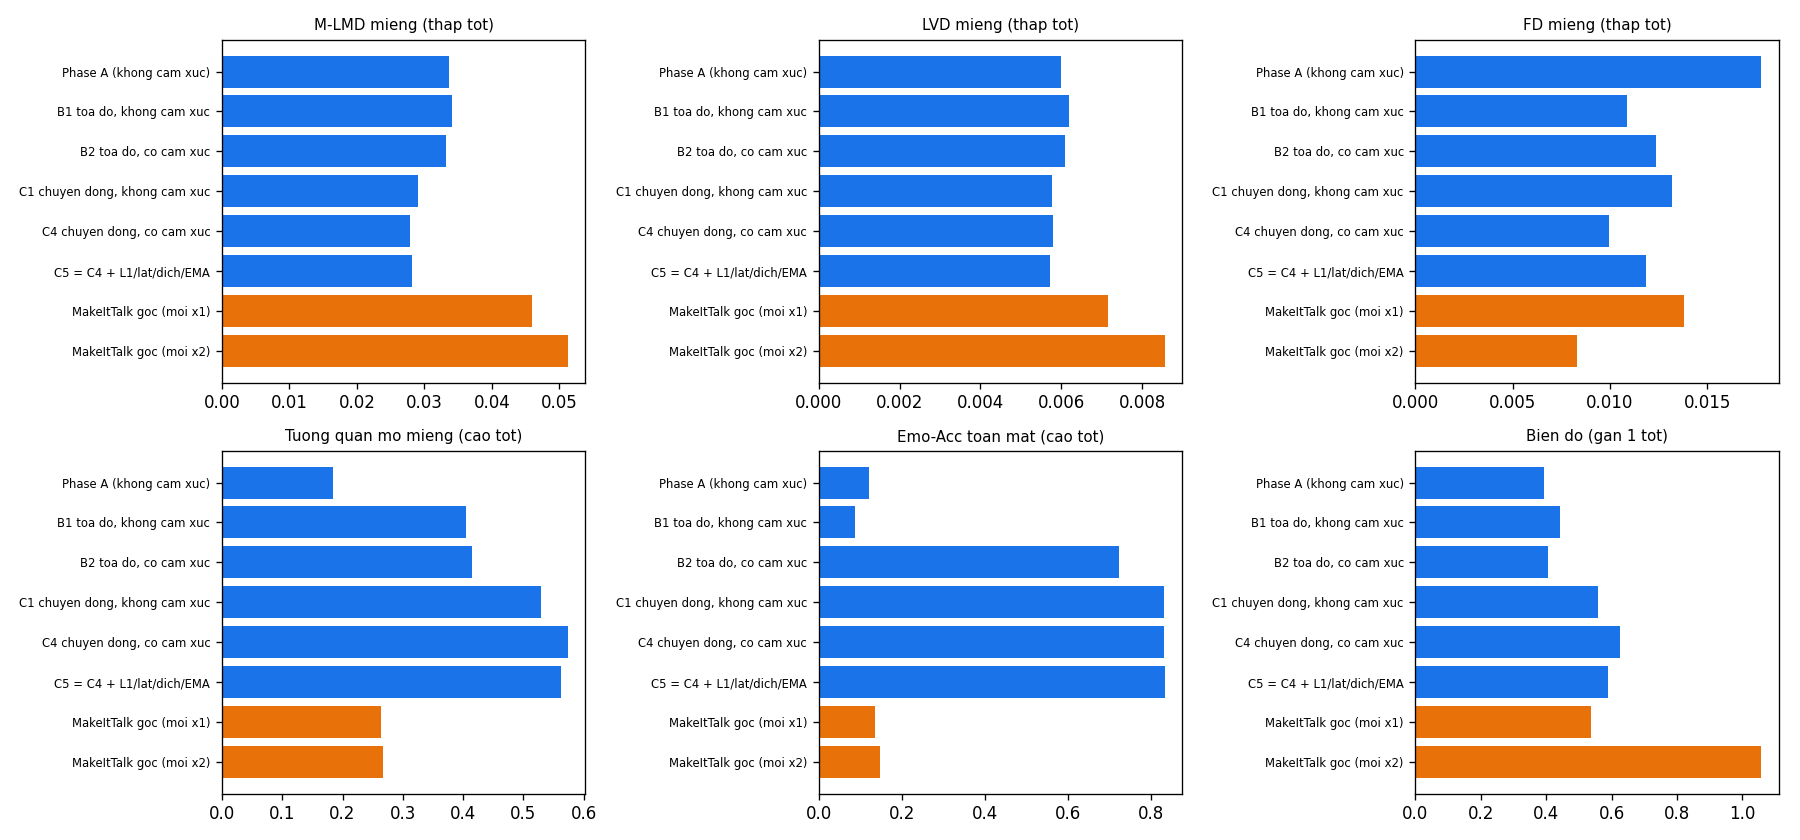

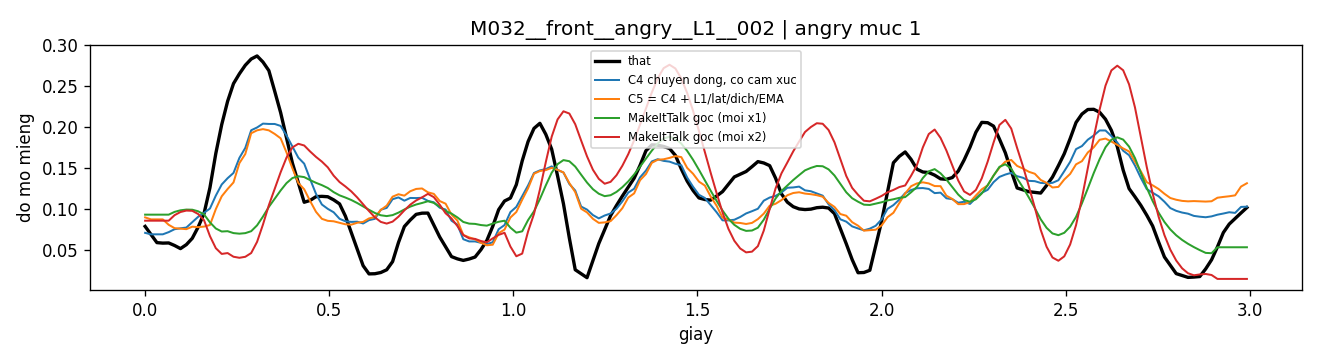

Da luu vao /content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseE


In [ ]:
COLS = [('LMD', 'LMD toan mat', 'min'), ('LMD_mieng', 'LMD mieng', 'min'), ('M_LMD_mieng', 'M-LMD mieng', 'min'),
        ('LVD_mieng', 'LVD mieng', 'min'), ('Rung', 'Rung (~1)', 'one'), ('Bien_do', 'Bien do (~1)', 'one'),
        ('Tuong_quan', 'Tuong quan', 'max'), ('FD_mieng', 'FD mieng', 'min'), ('Khep_khi_im', 'Khep khi im', 'min'),
        ('Emo_Acc', 'Emo-Acc', 'max'), ('Emo_Acc_cd', 'Emo-Acc chuyen dong', 'max')]


def table(R, title, ci=None):
    names = list(R)
    best = {}
    for k, _, how in COLS:
        v = np.array([R[n][k] for n in names], float)
        best[k] = names[int(np.nanargmin(np.abs(v - 1)) if how == 'one' else (np.nanargmin(v) if how == 'min' else np.nanargmax(v)))]
    head = '| Mo hinh | Tham so | ' + ' | '.join(c[1] for c in COLS) + ' |'
    lines = ['**%s**' % title, '', head, '|' + ' :--- |' * (len(COLS) + 2)]
    for n in names:
        cells_ = []
        for k, _, _ in COLS:
            v = R[n][k]; s_ = ('%.4f' % v) if k in ('LMD', 'LMD_mieng', 'M_LMD_mieng', 'LVD_mieng', 'Khep_khi_im') else ('%.3f' % v)
            if ci and k in ci.get(n, {}):                     # Phase H: khoang tin cay 95% (bootstrap theo clip)
                f_ = '%.4f' if k in ('LMD', 'LMD_mieng', 'M_LMD_mieng', 'LVD_mieng', 'Khep_khi_im') else '%.3f'
                s_ += ' [%s, %s]' % (f_ % ci[n][k][0], f_ % ci[n][k][1])
            cells_.append('**%s**' % s_ if best[k] == n else s_)
        p = NPARAM.get(n.split(' (moi')[0] if n.startswith('MakeItTalk') else n, np.nan)
        lines.append('| %s | %s | %s |' % (n, '%.2fM' % (p / 1e6) if p == p else '-', ' | '.join(cells_)))
    return '\n'.join(lines)


_T8 = ' - tap (b): ca 8 cam xuc, chi clip co emotion2vec+' if KEEP3 else ''
txt = [table(RES, 'Bang 1 - Toan bo %d clip test (%d speaker chua tung thay)' % (len(EVAL_IDS), len(SPLIT['test'])) + _T8,
             CI.get('test'))]
if RES_MIT:
    txt.append(table(RES_MIT, 'Bang 2 - So voi MakeItTalk goc tren cung %d clip test' % len(EVAL_MIT) + _T8, CI.get('mit')))
if EXCL_NOTE:
    txt.append('So sanh cong bang: MOI dong trong cac bang tinh tren CUNG tap clip (%s)' % EXCL_NOTE)
if KEEP3:                                                                 # Phase H: tap (a) 3 lop cua SpEx-KD
    _T3 = 'tap (a): chi clip %s (3 lop cua SpEx-KD)' % '/'.join(EMO_NAMES[k] for k in KEEP3)
    txt.append(table(RES3, 'Bang 1a - %s, %d clip test' % (_T3, len(IDS3)), CI.get('test3')))
    if RES_MIT3:
        txt.append(table(RES_MIT3, 'Bang 2a - So voi MakeItTalk goc, %s, %d clip' % (_T3, len(MIT3)), CI.get('mit3')))
    txt.append('Tran tren Emo-Acc tap (a): toan mat %.3f, chuyen dong %.3f' % (GT_EMO3['full'][0], GT_EMO3['motion'][0]))
if CHAIN_INFO:
    txt.insert(0, 'Phase H: chuoi demo = kep PCA mieng-ham %.1f sigma + lam muot %d ms (khong silence gate / gioi han pixel)%s%s'
               % (DEMO_MC['prior_clamp'], DEMO_MC['smooth_ms'],
                  ' | gain %s, thu tu %s, kep %.1f sigma' % (CHAIN_INFO['gain']['chosen'], CHAIN_INFO['gain']['order'],
                                                             CHAIN_INFO['gain']['prior_clamp']) if CHAIN_INFO['gain'] else '',
                  ' | %s: %s' % (ELSA_NAME, CHAIN_INFO['elsa_note']) if ELSA_NAME else ''))
if CI:
    txt.append('Trong ngoac vuong: khoang tin cay 95%% (bootstrap theo clip, %d lan, cung mau clip cho moi dong)' % N_BOOT)
if WILCOX:
    txt.append('\n'.join(['**Wilcoxon ghep cap theo clip (2 phia): %s vs MakeItTalk goc**' % ELSA_NAME, '',
                          '| MakeItTalk | Tap | Chi so | n clip | median ELSA | median MakeItTalk | p |', '|' + ' :--- |' * 7]
                         + ['| %s | %s | %s | %d | %.4f | %.4f | %.3g |' % (w_['mit'], w_['tap'], w_['chi_so'], w_['n_clip'],
                                                                            w_['median_elsa'], w_['median_mit'], w_['p']) for w_ in WILCOX]))
txt.append('Tran tren Emo-Acc (bo phan loai tren landmark THAT test): toan mat %.3f, chuyen dong %.3f'
           % (GT_EMO['full'][0], GT_EMO['motion'][0]))
txt.append('Toc do 1 s audio: ' + '; '.join('%s %s' % (n, ', '.join('%s %.1f ms' % (k, 1000 * v) for k, v in r.items()))
                                            for n, r in SPEED.items()))
if SPEED_FULL:                                                            # Phase H: toc do toan he thong dong ELSA
    _P = ['mel', 'emotion2vec+', 'SpEx-KD', 'C4', 'hau xu ly', 'tong']
    txt.append('\n'.join(['**Toc do toan he thong - %s, 1 s audio (ms; warm-up %d, trung binh %d lan)**' % (ELSA_NAME, SPEED_FULL['warmup'],
                                                                                                      SPEED_FULL['reps']), '',
                          SPEED_FULL['pipeline'] + ' (' + SPEED_FULL['note'] + ')', '',
                          '| Thiet bi | ' + ' | '.join(_P) + ' |', '|' + ' :--- |' * (len(_P) + 1)]
                         + ['| %s | %s |' % (d, ' | '.join('%.1f' % r[k] for k in _P)) for d, r in SPEED_FULL['ms'].items()]
                         + ['', '| Thanh phan | Tham so |', '| :--- | :--- |']
                         + ['| %s | %.2fM |' % (k, v / 1e6) for k, v in SPEED_FULL['params'].items()]
                         + ['| **Tong (gom ca emotion2vec+)** | **%.2fM** (huan luyen %.2fM) |' % (SPEED_FULL['params_total'] / 1e6,
                                                                                                SPEED_FULL['params_trained'] / 1e6)]))
MD = '\n\n'.join(txt)
print(MD)
(OUT / 'phaseE_table.md').write_text(MD)
import csv
with open(OUT / 'phaseE_table.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['bang', 'mo_hinh', 'tham_so'] + [c[0] for c in COLS] + ['n_clip'])
    for tag, R in (('test_day_du', RES), ('tap_con_MakeItTalk', RES_MIT)) + EXTRA_TABLES:
        for n, r in R.items():
            w.writerow([tag, n, NPARAM.get(n.split(' (moi')[0] if n.startswith('MakeItTalk') else n, '')] + [r[c[0]] for c in COLS] + [r['n_clip']])
(OUT / 'phaseE_results.json').write_text(json.dumps(dict(test=RES, test_subset_makeittalk=RES_MIT, gt_emo=GT_EMO, speed=SPEED,
                                                        params=NPARAM, split=SPLIT, mit_lag=globals().get('LAG'), seed=SEED, deterministic=DETERMINISTIC,
                                                        **({'phaseH': CHAIN_INFO} if CHAIN_INFO else {}),
                                                        **({'test_3_lop': RES3, 'test_subset_makeittalk_3_lop': RES_MIT3,
                                                            'gt_emo_3_lop': GT_EMO3} if KEEP3 else {}),
                                                        **({'ci95': CI, 'n_boot': N_BOOT} if CI else {}),
                                                        **({'wilcoxon': WILCOX} if WILCOX else {}),
                                                        **({'ci_check_ngoai_ci': CI_CHECK} if CI else {}),
                                                        **({'speed_full_elsa': SPEED_FULL} if SPEED_FULL else {})),
                                                   indent=1, ensure_ascii=False, default=float))
if CI:
    with open(OUT / 'phaseE_ci95.csv', 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['bang', 'mo_hinh', 'chi_so', 'gia_tri', 'ci95_thap', 'ci95_cao'])
        _R = dict(test=RES, mit=RES_MIT, test3=RES3, mit3=RES_MIT3)
        for tag, d in CI.items():
            for n, r in d.items():
                for k, (lo, hi) in r.items():
                    w.writerow([tag, n, k, _R[tag][n].get(k), lo, hi])

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
R = RES_MIT if RES_MIT else RES
keys = [('M_LMD_mieng', 'M-LMD mieng (thap tot)'), ('LVD_mieng', 'LVD mieng (thap tot)'), ('FD_mieng', 'FD mieng (thap tot)'),
        ('Tuong_quan', 'Tuong quan mo mieng (cao tot)'), ('Emo_Acc', 'Emo-Acc toan mat (cao tot)'), ('Bien_do', 'Bien do (gan 1 tot)')]
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, (k, t) in zip(axs.ravel(), keys):
    names = list(R); v = [R[n][k] for n in names]
    ax.barh(range(len(names)), v, color=['#e8710a' if n.startswith('MakeItTalk') else '#1a73e8' for n in names])
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=7); ax.set_title(t, fontsize=9); ax.invert_yaxis()
fig.tight_layout(); fig.savefig(OUT / 'phaseE_bars.png', dpi=120); plt.close(fig)

# vi du do mo mieng theo thoi gian tren 1 clip cam xuc
ci = next((i for i in (MIT_IDX or ALL_IDS) if DTE['clips'][i]['emo'] > 0), 0); c = DTE['clips'][ci]
ref = DTE['refs'][c['sp']]; t_ = np.arange(c['n']) / 62.5
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(t_, mouth_open(DTE['raw'][c['pos']:c['pos'] + c['n']] + ref), 'k-', lw=2, label='that')
for n, P in ALL.items():
    if n.startswith(('C4', 'C5', 'MakeItTalk', 'ELSA')):
        ax.plot(t_, mouth_open(P[c['pos']:c['pos'] + c['n']] + ref), lw=1.2, label=n)
ax.set_xlabel('giay'); ax.set_ylabel('do mo mieng'); ax.set_title('%s | %s muc %d' % (c['name'], EMO_NAMES[c['emo']], c['lvl']))
ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(OUT / 'phaseE_mouth_example.png', dpi=120); plt.close(fig)
if IN_COLAB:
    from IPython.display import Image, display
    display(Image(str(OUT / 'phaseE_bars.png'))); display(Image(str(OUT / 'phaseE_mouth_example.png')))
print('Da luu vao', OUT)